# Caso 1 · Cauce: clasificación automática de mensajes de clientes

**Integrantes:**

- Andruszyszyn Emanuel
- Quirós Juan

Este notebook sigue las consignas del enunciado (pasos 1 a 20). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.limpieza import limpiar_texto
from src.naive_bayes import NaiveBayesMultinomial, terminos_mas_indicativos
from src.derivacion import REVISION, derivar, evaluar_derivacion

In [2]:
import sys
import sklearn
print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

Python: 3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]
scikit-learn: 1.9.1
NumPy: 2.5.4
pandas: 3.0.6


### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [3]:
!python -m pytest -q --tb=no -rf

...............................                                          [100%]
31 passed in 1.98s


## Parte A · Exploración y línea base

**Paso 1.** Carguen `datos/mensajes_historicos.csv` e informen filas, nulos, mensajes vacíos, duplicados (mismo `id_cliente` y mismo `texto`), distribución de `equipo_final`, distribución por canal y cantidad de palabras por clase.

,Cantidad
Registros,8200
Textos nulos,11
Textos vacíos (incluye nulos y espacios),18
Duplicados por cliente y texto,200


,Tipo de dato,Nulos
id_mensaje,str,0
fecha_hora,str,0
id_cliente,str,0
canal,str,0
texto,str,11
equipo_derivado,str,0
equipo_final,str,0


,Mensajes,Porcentaje
equipo_final,,
transferencias,2552,31.12
tarjeta,2057,25.09
cuenta_acceso,1648,20.10
prestamos_inversiones,1029,12.55
fraude,914,11.15


,Mensajes
canal,
app_chat,3676
whatsapp,2499
email,1163
formulario_web,862


,Mensajes,Promedio,Mediana,Mínimo,Máximo
equipo_final,,,,,
cuenta_acceso,1648,13.87,13.0,0,46
fraude,914,18.22,17.0,0,50
prestamos_inversiones,1029,12.58,12.0,0,33
tarjeta,2057,14.81,14.0,0,42
transferencias,2552,16.95,17.0,0,41


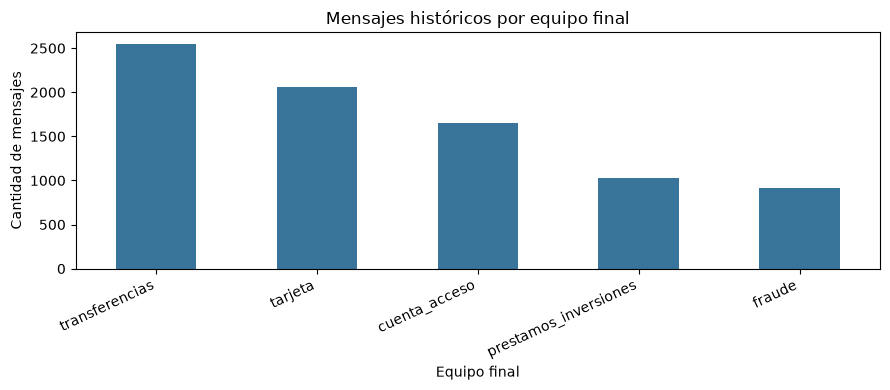

In [4]:
from IPython.display import display

df_original = pd.read_csv("datos/mensajes_historicos.csv")
cantidad_palabras_original = df_original["texto"].fillna("").str.split().str.len()
mensajes_vacios = df_original["texto"].fillna("").str.strip().eq("")
duplicados = df_original.duplicated(subset=["id_cliente", "texto"], keep="first")

resumen_original = pd.Series({
    "Registros": len(df_original),
    "Textos nulos": df_original["texto"].isna().sum(),
    "Textos vacíos (incluye nulos y espacios)": mensajes_vacios.sum(),
    "Duplicados por cliente y texto": duplicados.sum(),
}, name="Cantidad").to_frame()
display(resumen_original)
display(pd.DataFrame({
    "Tipo de dato": df_original.dtypes.astype(str),
    "Nulos": df_original.isna().sum(),
}))

distribucion_equipos = df_original["equipo_final"].value_counts().to_frame("Mensajes")
distribucion_equipos["Porcentaje"] = 100 * distribucion_equipos["Mensajes"] / len(df_original)
display(distribucion_equipos.round(2))
display(df_original["canal"].value_counts().to_frame("Mensajes"))

palabras_por_clase = (
    df_original.assign(palabras=cantidad_palabras_original)
    .groupby("equipo_final")["palabras"]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(columns={"count": "Mensajes", "mean": "Promedio", "median": "Mediana", "min": "Mínimo", "max": "Máximo"})
)
display(palabras_por_clase.round(2))

ax = distribucion_equipos["Mensajes"].plot.bar(figsize=(9, 4), color="#39749b")
ax.set_title("Mensajes históricos por equipo final")
ax.set_xlabel("Equipo final")
ax.set_ylabel("Cantidad de mensajes")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Transferencias concentra la mayor cantidad de mensajes y fraude es la clase con menos ejemplos. Hay textos nulos o vacíos y registros repetidos por cliente y texto. Los mensajes de fraude tienen el mayor promedio de palabras; los de préstamos e inversiones, el menor. Las tablas muestran los datos originales, antes de quitar registros.

**Paso 2.** Línea base de la mesa de entrada (`equipo_derivado` contra `equipo_final`): exactitud, F1 macro, matriz de confusión normalizada por fila y porcentaje de fraude derivado a otro equipo.

In [5]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

clases = np.sort(df_original["equipo_final"].unique())
y_real_manual = df_original["equipo_final"]
y_derivado_manual = df_original["equipo_derivado"]
es_fraude = y_real_manual.eq("fraude")
fraude_otro_equipo = es_fraude & y_derivado_manual.ne("fraude")
correctos_manuales = y_real_manual.eq(y_derivado_manual)

linea_base = pd.Series({
    "Mensajes originales": len(df_original),
    "Derivaciones correctas": correctos_manuales.sum(),
    "Derivaciones incorrectas": (~correctos_manuales).sum(),
    "Accuracy (%)": 100 * accuracy_score(y_real_manual, y_derivado_manual),
    "Errores (%)": 100 * (~correctos_manuales).mean(),
    "F1 macro": f1_score(y_real_manual, y_derivado_manual, labels=clases, average="macro", zero_division=0),
    "Mensajes reales de fraude": es_fraude.sum(),
    "Fraudes enviados a otro equipo": fraude_otro_equipo.sum(),
    "Fraudes enviados a otro equipo (%)": 100 * fraude_otro_equipo.sum() / es_fraude.sum(),
}, name="Resultado").to_frame()
display(linea_base.round(4))

matriz_manual = pd.DataFrame(
    confusion_matrix(y_real_manual, y_derivado_manual, labels=clases),
    index=pd.Index(clases, name="Equipo real"),
    columns=pd.Index(clases, name="Equipo derivado"),
)
matriz_manual_porcentaje = 100 * matriz_manual.div(matriz_manual.sum(axis=1), axis=0)
print("Matriz de confusión: cantidad de mensajes")
display(matriz_manual)
print("Matriz normalizada por fila: porcentaje de cada equipo real")
display(matriz_manual_porcentaje.round(2))

,Resultado
Mensajes originales,8200.0000
Derivaciones correctas,6774.0000
Derivaciones incorrectas,1426.0000
Accuracy (%),82.6098
Errores (%),17.3902
F1 macro,0.8166
Mensajes reales de fraude,914.0000
Fraudes enviados a otro equipo,290.0000
Fraudes enviados a otro equipo (%),31.7287


Matriz de confusión: cantidad de mensajes


Equipo derivado,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,1347,92,0,97,112
fraude,52,624,0,153,85
prestamos_inversiones,23,0,890,25,91
tarjeta,115,80,0,1722,140
transferencias,77,84,87,113,2191


Matriz normalizada por fila: porcentaje de cada equipo real


Equipo derivado,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,81.74,5.58,0.00,5.89,6.80
fraude,5.69,68.27,0.00,16.74,9.30
prestamos_inversiones,2.24,0.00,86.49,2.43,8.84
tarjeta,5.59,3.89,0.00,83.71,6.81
transferencias,3.02,3.29,3.41,4.43,85.85


La mesa de entrada acierta el 82,61% de las derivaciones y se equivoca en el 17,39%. De los 914 fraudes reales, 290 llegan a otro equipo (31,73%). Esta es la línea base manual: todavía no evaluamos un modelo sobre el histórico. Tiene sentido comparar una clasificación automática si permite reducir estos errores, especialmente los de fraude.

**Paso 3.** Eliminen los duplicados conservando el primero y expliquen por qué se hace antes de dividir.

In [6]:
df_sin_duplicados = df_original.drop_duplicates(subset=["id_cliente", "texto"], keep="first").copy()
duplicados_restantes = df_sin_duplicados.duplicated(subset=["id_cliente", "texto"]).sum()

display(pd.Series({
    "Registros originales": len(df_original),
    "Duplicados eliminados": len(df_original) - len(df_sin_duplicados),
    "Registros restantes": len(df_sin_duplicados),
    "Duplicados restantes por cliente y texto": duplicados_restantes,
}, name="Cantidad").to_frame())
assert duplicados_restantes == 0

,Cantidad
Registros originales,8200
Duplicados eliminados,200
Registros restantes,8000
Duplicados restantes por cliente y texto,0


Quitamos 200 duplicados y quedaron 8.000 mensajes, conservando la primera aparición. Lo hacemos antes de separar entrenamiento y prueba para evitar que un registro repetido aparezca en ambos conjuntos y mejore artificialmente la evaluación. Trabajamos sobre una copia; no cambiamos el CSV ni sus etiquetas.

## Parte B · Limpieza de texto (`src/limpieza.py`)

**Paso 4.** Implementen `quitar_tildes` y `limpiar_texto` en `src/limpieza.py` hasta que pasen `tests/test_limpieza.py`. Muestren aquí 5 ejemplos de texto original y limpio.

In [7]:
import subprocess
import sys

pruebas_limpieza = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_limpieza.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_limpieza.stdout.strip())

# Ejemplos preparados para mostrar las reglas, sin tomar mensajes de clientes.
ejemplos_limpieza = [
    "¡NO PUEDO ENTRAR A MI CUENTA! 😡",
    "Me cobraron $ 15.000 dos veces.",
    "Transferí Gs. 8.350,50 y pagué USD20.",
    "Escribí a ayuda@example.com y entré a https://example.com/ayuda.",
    "La operación 123456 sigue pendiente.\nNecesito   ayuda.",
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({
        "Texto original (inventado)": ejemplos_limpieza,
        "Texto limpio": [limpiar_texto(texto) for texto in ejemplos_limpieza],
    }))

...............                                                          [100%]
15 passed in 0.02s


,Texto original (inventado),Texto limpio
0,¡NO PUEDO ENTRAR A MI CUENTA! 😡,no puedo entrar a mi cuenta
1,Me cobraron $ 15.000 dos veces.,me cobraron _monto_ dos veces
2,"Transferí Gs. 8.350,50 y pagué USD20.",transferi _monto_ y pague _monto_
3,Escribí a ayuda@example.com y entré a https://example.com/ayuda.,escribi a _email_ y entre a _url_
4,La operación 123456 sigue pendiente.\nNecesito ayuda.,la operacion _num_ sigue pendiente necesito ayuda


Los cinco ejemplos son inventados. La limpieza unifica mayúsculas y tildes, reemplaza URL, correos, montos y números por tokens y compacta espacios. Los guiones bajos de esos tokens se conservan. No quitamos palabras comunes ni agregamos otras transformaciones.

**Paso 5.** Creen la columna `texto_limpio`. Los mensajes con menos de dos palabras se excluyen del entrenamiento y van a revisión humana: ¿cuántos son y qué contienen?

In [8]:
df_preparado = df_sin_duplicados.copy()
df_preparado["texto_limpio"] = df_preparado["texto"].map(limpiar_texto)
df_preparado["cantidad_palabras_limpias"] = df_preparado["texto_limpio"].str.split().str.len()
mascara_revision = df_preparado["cantidad_palabras_limpias"].lt(2)
mascara_entrenamiento = ~mascara_revision

# Se conservan los índices y los identificadores en memoria para ubicar cada registro.
df_revision = df_preparado.loc[mascara_revision].copy()
df_entrenamiento = df_preparado.loc[mascara_entrenamiento].copy()

display(pd.Series({
    "Mensajes sin duplicados": len(df_preparado),
    "Mensajes con texto_limpio calculado": df_preparado["texto_limpio"].notna().sum(),
    "Textos limpios no vacíos": df_preparado["texto_limpio"].ne("").sum(),
    "Mensajes con menos de dos palabras (revisión)": mascara_revision.sum(),
    "Mensajes aptos para entrenamiento": mascara_entrenamiento.sum(),
}, name="Cantidad").to_frame())
display(df_revision["equipo_final"].value_counts().reindex(clases, fill_value=0).to_frame("Mensajes cortos"))

tipo_contenido_corto = np.select(
    [
        df_revision["texto_limpio"].eq(""),
        df_revision["texto_limpio"].eq("_num_"),
        df_revision["texto_limpio"].eq("_monto_"),
        df_revision["texto_limpio"].eq("_url_"),
        df_revision["texto_limpio"].eq("_email_"),
    ],
    ["Vacío después de limpiar", "Sólo número", "Sólo monto", "Sólo URL", "Sólo correo"],
    default="Una palabra",
)
display(pd.Series(tipo_contenido_corto, name="Contenido").value_counts().to_frame("Mensajes"))
assert len(df_entrenamiento) + len(df_revision) == len(df_preparado)
assert df_entrenamiento["cantidad_palabras_limpias"].ge(2).all()

,Cantidad
Mensajes sin duplicados,8000
Mensajes con texto_limpio calculado,8000
Textos limpios no vacíos,7952
Mensajes con menos de dos palabras (revisión),70
Mensajes aptos para entrenamiento,7930


,Mensajes cortos
equipo_final,
cuenta_acceso,16
fraude,6
prestamos_inversiones,14
tarjeta,18
transferencias,16


,Mensajes
Contenido,
Vacío después de limpiar,48
Una palabra,22


La limpieza se aplicó a los 8.000 mensajes sin duplicados. Quedaron 7.952 textos no vacíos; 70 mensajes tienen menos de dos palabras y se reservan para revisión humana. De esos 70, 48 quedan vacíos y 22 contienen una sola palabra: no alcanzan para describir el problema con suficiente contexto. Los 7.930 restantes quedan preparados para entrenamiento, sin dividirlos ni entrenar un modelo todavía. Las máscaras y las copias mantienen los índices e identificadores originales, pero sólo mostramos agregados.

## Parte C · Naive Bayes desde cero (`src/naive_bayes.py`)

**Paso 6.** Implementen `log_suma_exp`, `NaiveBayesMultinomial` y `terminos_mas_indicativos` hasta que pasen `tests/test_naive_bayes.py`.

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

pruebas_naive_bayes = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_naive_bayes.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_naive_bayes.stdout.strip())

# Demostración con mensajes inventados; no se entrena con el histórico de Cauce.
textos_demo = [
    "no puedo ingresar a mi cuenta",
    "necesito recuperar la clave de mi cuenta",
    "me rechazaron la tarjeta",
    "no puedo activar mi tarjeta",
    "no reconozco esta transferencia",
    "hicieron una transferencia que no reconozco",
]
etiquetas_demo = ["cuenta_acceso", "cuenta_acceso", "tarjeta", "tarjeta", "fraude", "fraude"]
vectorizador_demo = CountVectorizer()
X_demo = vectorizador_demo.fit_transform([limpiar_texto(texto) for texto in textos_demo])
modelo_demo = NaiveBayesMultinomial(alpha=1).fit(X_demo, etiquetas_demo)

consultas_demo = [
    "no puedo ingresar a mi cuenta",
    "me rechazaron la tarjeta",
    "no reconozco esta transferencia",
]
X_consultas_demo = vectorizador_demo.transform([limpiar_texto(texto) for texto in consultas_demo])
probabilidades_demo = modelo_demo.predict_proba(X_consultas_demo)
predicciones_demo = modelo_demo.predict(X_consultas_demo)
resultado_demo = pd.DataFrame({"Mensaje inventado": consultas_demo, "Clase predicha": predicciones_demo})
for indice, clase in enumerate(modelo_demo.classes_):
    resultado_demo[f"P({clase})"] = probabilidades_demo[:, indice]
display(resultado_demo.round(4))
np.testing.assert_allclose(probabilidades_demo.sum(axis=1), 1.0)

............                                                             [100%]
12 passed in 2.26s


,Mensaje inventado,Clase predicha,P(cuenta_acceso),P(fraude),P(tarjeta)
0,no puedo ingresar a mi cuenta,cuenta_acceso,0.8069,0.0464,0.1467
1,me rechazaron la tarjeta,tarjeta,0.0514,0.0333,0.9153
2,no reconozco esta transferencia,fraude,0.0267,0.9337,0.0396


Naive Bayes suma conteos de términos por clase, aplica suavizado y combina logaritmos para evitar underflow. `log_suma_exp` normaliza los puntajes para obtener probabilidades; la clase con la mayor probabilidad es la predicción. Las pruebas verifican el cálculo manual, la equivalencia numérica con scikit-learn, las matrices dispersas y la compatibilidad con Pipeline y GridSearchCV. La tabla usa un conjunto didáctico pequeño: muestra que el código funciona, pero sus probabilidades no son una evaluación del caso Cauce. El análisis de términos del histórico queda para el paso 9.

**Paso 7.** División 80/20 estratificada por `equipo_final` con `random_state=42`.

In [10]:
from sklearn.model_selection import train_test_split

textos_entrenamiento, textos_prueba, etiquetas_entrenamiento, etiquetas_prueba = train_test_split(
    df_entrenamiento["texto_limpio"], df_entrenamiento["equipo_final"],
    test_size=0.20, random_state=SEMILLA, stratify=df_entrenamiento["equipo_final"],
)
assert SEMILLA == 42
assert textos_entrenamiento.index.intersection(textos_prueba.index).empty
assert textos_entrenamiento.index.intersection(df_revision.index).empty
assert textos_prueba.index.intersection(df_revision.index).empty
assert textos_entrenamiento.str.split().str.len().ge(2).all()
assert textos_prueba.str.split().str.len().ge(2).all()
assert textos_entrenamiento.index.equals(etiquetas_entrenamiento.index)
assert textos_prueba.index.equals(etiquetas_prueba.index)

resumen_division = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Mensajes": [len(textos_entrenamiento), len(textos_prueba)],
})
resumen_division["Porcentaje de los mensajes aptos"] = 100 * resumen_division["Mensajes"] / len(df_entrenamiento)
display(resumen_division)

distribucion_division = pd.DataFrame({
    "Entrenamiento": etiquetas_entrenamiento.value_counts(),
    "Prueba": etiquetas_prueba.value_counts(),
}).reindex(clases)
distribucion_division["Entrenamiento (%)"] = 100 * distribucion_division["Entrenamiento"] / len(etiquetas_entrenamiento)
distribucion_division["Prueba (%)"] = 100 * distribucion_division["Prueba"] / len(etiquetas_prueba)
display(distribucion_division.round(2))

,Conjunto,Mensajes,Porcentaje de los mensajes aptos
0,Entrenamiento,6344,80.0
1,Prueba,1586,20.0


,Entrenamiento,Prueba,Entrenamiento (%),Prueba (%)
equipo_final,,,,
cuenta_acceso,1274,318,20.08,20.05
fraude,707,176,11.14,11.10
prestamos_inversiones,790,198,12.45,12.48
tarjeta,1598,400,25.19,25.22
transferencias,1975,494,31.13,31.15


Separamos los mensajes aptos antes de ajustar el vectorizador. La estratificación mantiene aproximadamente el porcentaje de cada equipo en ambos conjuntos. Conservamos los índices para comprobar que no comparten registros y que los mensajes reservados para revisión humana quedan fuera.

**Paso 8.** `CountVectorizer` + su clase y la de scikit-learn con `alpha=1`: muestren que predicen lo mismo en el 100% de los mensajes de prueba.

In [11]:
from sklearn.naive_bayes import MultinomialNB

vectorizador_base = CountVectorizer()
X_entrenamiento_base = vectorizador_base.fit_transform(textos_entrenamiento)
X_prueba_base = vectorizador_base.transform(textos_prueba)
modelo_nb_base = NaiveBayesMultinomial(alpha=1).fit(X_entrenamiento_base, etiquetas_entrenamiento)
modelo_nb_referencia = MultinomialNB(alpha=1).fit(X_entrenamiento_base, etiquetas_entrenamiento)

np.testing.assert_array_equal(modelo_nb_base.classes_, modelo_nb_referencia.classes_)
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({
        "Dato": ["Clases", "Orden de clases", "Términos del vocabulario", "Matriz de entrenamiento", "Matriz de prueba"],
        "Valor": [len(modelo_nb_base.classes_), ", ".join(modelo_nb_base.classes_),
                  len(vectorizador_base.get_feature_names_out()), X_entrenamiento_base.shape, X_prueba_base.shape],
    }))

# Prueba se usa aquí para verificar la implementación, sin medir su desempeño.
predicciones_nb_base = modelo_nb_base.predict(X_prueba_base)
predicciones_nb_referencia = modelo_nb_referencia.predict(X_prueba_base)
coincidencias_nb = predicciones_nb_base == predicciones_nb_referencia
probabilidades_nb_base = modelo_nb_base.predict_proba(X_prueba_base)
probabilidades_nb_referencia = modelo_nb_referencia.predict_proba(X_prueba_base)
np.testing.assert_allclose(probabilidades_nb_base, probabilidades_nb_referencia, rtol=1e-8, atol=1e-10)
assert coincidencias_nb.all()
display(pd.Series({
    "Predicciones comparadas": len(coincidencias_nb),
    "Coincidencias": coincidencias_nb.sum(),
    "Coincidencia (%)": 100 * coincidencias_nb.mean(),
    "Diferencia máxima absoluta entre probabilidades": f"{np.abs(probabilidades_nb_base - probabilidades_nb_referencia).max():.3e}",
}, name="Resultado", dtype=object).to_frame())

,Dato,Valor
0,Clases,5
1,Orden de clases,"cuenta_acceso, fraude, prestamos_inversiones, tarjeta, transferencias"
2,Términos del vocabulario,1399
3,Matriz de entrenamiento,"(6344, 1399)"
4,Matriz de prueba,"(1586, 1399)"


,Resultado
Predicciones comparadas,1586
Coincidencias,1586
Coincidencia (%),100.0
Diferencia máxima absoluta entre probabilidades,1.421e-14


La coincidencia comprueba que ambas implementaciones hacen la misma predicción, no que acierten todas las etiquetas reales. Esta comparación no se usa para elegir parámetros, ajustar umbrales ni decidir el modelo final. El vocabulario se aprendió sólo con entrenamiento y la proximidad de las probabilidades se comprobó con una tolerancia numérica.

**Paso 9.** Los 10 términos más indicativos de cada clase y su interpretación para el negocio.

In [12]:
vocabulario_base = vectorizador_base.get_feature_names_out()
terminos_por_clase = terminos_mas_indicativos(modelo_nb_base, vocabulario_base, n=10)
assert set(terminos_por_clase) == set(clases)
assert all(len(terminos) == 10 for terminos in terminos_por_clase.values())
tabla_terminos = pd.DataFrame({
    "Categoría": list(terminos_por_clase),
    "Términos más indicativos": [", ".join(terminos) for terminos in terminos_por_clase.values()],
})
with pd.option_context("display.max_colwidth", None):
    display(tabla_terminos)

,Categoría,Términos más indicativos
0,cuenta_acceso,"actualizar, nuevo, validar, reconoce, contrasena, entrar, modifico, validacion, token, ingresar"
1,fraude,"robaron, diciendo, yo, reconozco, pidiendo, ahora, mios, son, aparecen, nombre"
2,prestamos_inversiones,"preaprobado, las, cuotas, ahorros, invertir, punitorios, invierto, vi, pagos, conviene"
3,tarjeta,"cajero, virtual, entrega, nueva, solo, insertandola, fisica, acerco, correo, contactless"
4,transferencias,"transferir, acredito, limite, qr, corresponsal, transferencia, deposite, programada, equivocada, diario"


Los términos se obtienen del modelo y del vocabulario aprendidos únicamente con entrenamiento. El puntaje compara cada palabra con las otras clases; no es una lista de las palabras más frecuentes.

En cuenta_acceso aparecen términos como contrasena, entrar y validar. En fraude sobresalen robaron, reconozco y mios; expresan desconocimiento de operaciones, aunque palabras como yo o ahora dependen mucho del contexto. Cuotas, invertir y punitorios caracterizan préstamos e inversiones; cajero, contactless y virtual distinguen tarjeta; transferir, acredito y qr ayudan a reconocer transferencias. Una mención a una transferencia puede ser un reclamo operativo o un aviso de fraude: reconocer palabras aisladas no alcanza para interpretar todos los mensajes. También las cuotas pueden relacionarse con distintos productos.

## Parte D · Ajuste y comparación con KNN

**Paso 10.** `GridSearchCV` del pipeline `CountVectorizer` + `NaiveBayesMultinomial` (5 particiones estratificadas, `f1_macro`). Conclusión sobre cada hiperparámetro.

In [13]:
from sklearn.base import clone
from IPython.display import HTML
REPRODUCIR_BUSQUEDAS = False  # La revisión no realiza nuevas búsquedas.
if REPRODUCIR_BUSQUEDAS:
    from sklearn.pipeline import Pipeline
    from sklearn.model_selection import GridSearchCV, StratifiedKFold
    
    validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    particiones_cv = list(validacion.split(textos_entrenamiento, etiquetas_entrenamiento))
    assert all(set(ajuste).isdisjoint(evaluacion) for ajuste, evaluacion in particiones_cv)
    
    pipeline_nb = Pipeline([
        ("vec", CountVectorizer()),
        ("nb", NaiveBayesMultinomial()),
    ])
    grilla_nb = {
        "nb__alpha": [0.1, 0.5, 1.0, 2.0],
        "vec__ngram_range": [(1, 1), (1, 2)],
        "vec__min_df": [1, 2],
    }
    print("Grilla de Naive Bayes:", grilla_nb)
    busqueda_nb = GridSearchCV(
        pipeline_nb, grilla_nb, cv=particiones_cv, scoring="f1_macro",
        n_jobs=1, error_score="raise", refit=True,
    )
    busqueda_nb.fit(textos_entrenamiento, etiquetas_entrenamiento)
    modelo_nb_ajustado = busqueda_nb.best_estimator_
    resultados_cv_nb = pd.DataFrame(busqueda_nb.cv_results_)
    print("Mejores parámetros:", busqueda_nb.best_params_)
    print(f"Mejor F1 macro promedio de validación: {busqueda_nb.best_score_:.6f}")
    columnas_nb = ["param_nb__alpha", "param_vec__ngram_range", "param_vec__min_df", "mean_test_score", "std_test_score"]
    display(
        resultados_cv_nb.sort_values("mean_test_score", ascending=False, kind="stable")
        .head(5)[columnas_nb]
        .rename(columns={"param_nb__alpha": "alpha", "param_vec__ngram_range": "ngram_range",
                         "param_vec__min_df": "min_df", "mean_test_score": "F1 macro promedio",
                         "std_test_score": "Desvío entre particiones"})
        .round(6)
    )
    
    # Se cambia un parámetro por vez, manteniendo los otros en la mejor configuración.
    efectos_nb = []
    for parametro, valores in grilla_nb.items():
        for valor in valores:
            mascara = resultados_cv_nb[f"param_{parametro}"].map(lambda evaluado: evaluado == valor)
            for otro, mejor_valor in busqueda_nb.best_params_.items():
                if otro != parametro:
                    mascara &= resultados_cv_nb[f"param_{otro}"].map(lambda evaluado: evaluado == mejor_valor)
            fila = resultados_cv_nb.loc[mascara].iloc[0]
            efectos_nb.append({"Parámetro": parametro, "Valor": str(valor), "F1 macro promedio": fila["mean_test_score"]})
    display(pd.DataFrame(efectos_nb).round(6))
else:
    from sklearn.pipeline import Pipeline
    from sklearn.model_selection import GridSearchCV, StratifiedKFold
    validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    particiones_cv = list(validacion.split(textos_entrenamiento, etiquetas_entrenamiento))
    pipeline_nb = Pipeline([("vec", CountVectorizer()), ("nb", NaiveBayesMultinomial())])
    parametros_nb_congelados = {"nb__alpha": 0.1, "vec__ngram_range": (1, 2), "vec__min_df": 2}
    modelo_nb_ajustado = clone(pipeline_nb).set_params(**parametros_nb_congelados).fit(textos_entrenamiento, etiquetas_entrenamiento)
    print("Resultados registrados del Sprint 2; no se repitió la búsqueda.")
    resultados_registrados = [{'texto': "Grilla de Naive Bayes: {'nb__alpha': [0.1, 0.5, 1.0, 2.0], 'vec__ngram_range': [(1, 1), (1, 2)], 'vec__min_df': [1, 2]}\n"}, {'texto': "Mejores parámetros: {'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}\nMejor F1 macro promedio de validación: 0.935575\n"}, {'html': '<div>\n<style scoped>\n    .dataframe tbody tr th:only-of-type {\n        vertical-align: middle;\n    }\n\n    .dataframe tbody tr th {\n        vertical-align: top;\n    }\n\n    .dataframe thead th {\n        text-align: right;\n    }\n</style>\n<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>alpha</th>\n      <th>ngram_range</th>\n      <th>min_df</th>\n      <th>F1 macro promedio</th>\n      <th>Desvío entre particiones</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>3</th>\n      <td>0.1</td>\n      <td>(1, 2)</td>\n      <td>2</td>\n      <td>0.935575</td>\n      <td>0.006523</td>\n    </tr>\n    <tr>\n      <th>1</th>\n      <td>0.1</td>\n      <td>(1, 2)</td>\n      <td>1</td>\n      <td>0.935467</td>\n      <td>0.005661</td>\n    </tr>\n    <tr>\n      <th>7</th>\n      <td>0.5</td>\n      <td>(1, 2)</td>\n      <td>2</td>\n      <td>0.935093</td>\n      <td>0.004914</td>\n    </tr>\n    <tr>\n      <th>5</th>\n      <td>0.5</td>\n      <td>(1, 2)</td>\n      <td>1</td>\n      <td>0.934940</td>\n      <td>0.004809</td>\n    </tr>\n    <tr>\n      <th>9</th>\n      <td>1.0</td>\n      <td>(1, 2)</td>\n      <td>1</td>\n      <td>0.934298</td>\n      <td>0.005455</td>\n    </tr>\n  </tbody>\n</table>\n</div>'}, {'html': '<div>\n<style scoped>\n    .dataframe tbody tr th:only-of-type {\n        vertical-align: middle;\n    }\n\n    .dataframe tbody tr th {\n        vertical-align: top;\n    }\n\n    .dataframe thead th {\n        text-align: right;\n    }\n</style>\n<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>Parámetro</th>\n      <th>Valor</th>\n      <th>F1 macro promedio</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>0</th>\n      <td>nb__alpha</td>\n      <td>0.1</td>\n      <td>0.935575</td>\n    </tr>\n    <tr>\n      <th>1</th>\n      <td>nb__alpha</td>\n      <td>0.5</td>\n      <td>0.935093</td>\n    </tr>\n    <tr>\n      <th>2</th>\n      <td>nb__alpha</td>\n      <td>1.0</td>\n      <td>0.933230</td>\n    </tr>\n    <tr>\n      <th>3</th>\n      <td>nb__alpha</td>\n      <td>2.0</td>\n      <td>0.932804</td>\n    </tr>\n    <tr>\n      <th>4</th>\n      <td>vec__ngram_range</td>\n      <td>(1, 1)</td>\n      <td>0.929803</td>\n    </tr>\n    <tr>\n      <th>5</th>\n      <td>vec__ngram_range</td>\n      <td>(1, 2)</td>\n      <td>0.935575</td>\n    </tr>\n    <tr>\n      <th>6</th>\n      <td>vec__min_df</td>\n      <td>1</td>\n      <td>0.935467</td>\n    </tr>\n    <tr>\n      <th>7</th>\n      <td>vec__min_df</td>\n      <td>2</td>\n      <td>0.935575</td>\n    </tr>\n  </tbody>\n</table>\n</div>'}]
    for registro in resultados_registrados:
        if "html" in registro:
            display(HTML(registro["html"]))
        else:
            print(registro["texto"])


Resultados registrados del Sprint 2; no se repitió la búsqueda.
Grilla de Naive Bayes: {'nb__alpha': [0.1, 0.5, 1.0, 2.0], 'vec__ngram_range': [(1, 1), (1, 2)], 'vec__min_df': [1, 2]}

Mejores parámetros: {'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}
Mejor F1 macro promedio de validación: 0.935575



,alpha,ngram_range,min_df,F1 macro promedio,Desvío entre particiones
3,0.1,"(1, 2)",2,0.935575,0.006523
1,0.1,"(1, 2)",1,0.935467,0.005661
7,0.5,"(1, 2)",2,0.935093,0.004914
5,0.5,"(1, 2)",1,0.934940,0.004809
9,1.0,"(1, 2)",1,0.934298,0.005455


,Parámetro,Valor,F1 macro promedio
0,nb__alpha,0.1,0.935575
1,nb__alpha,0.5,0.935093
2,nb__alpha,1.0,0.933230
3,nb__alpha,2.0,0.932804
4,vec__ngram_range,"(1, 1)",0.929803
5,vec__ngram_range,"(1, 2)",0.935575
6,vec__min_df,1,0.935467
7,vec__min_df,2,0.935575


Probamos una grilla de 16 combinaciones. `alpha` controla el suavizado; `ngram_range` permite palabras individuales o también pares consecutivos; `min_df` exige que un término aparezca en uno o dos documentos para entrar al vocabulario. La búsqueda usa cinco particiones estratificadas del entrenamiento y F1 macro. La última tabla cambia un parámetro por vez manteniendo los demás en la mejor configuración. El pipeline vuelve a aprender el vocabulario dentro de cada partición. Conservamos el mejor estimador para continuar, sin calcular su rendimiento final en prueba.

La mejor combinación usa alpha=0.1, unigramas y bigramas, y min_df=2. Manteniendo los otros parámetros en esos valores, los bigramas mejoraron el promedio frente a usar sólo palabras individuales. El suavizado bajo obtuvo el mayor promedio de la grilla; al aumentarlo, el promedio fue algo menor. Cambiar min_df de uno a dos documentos produjo una diferencia muy pequeña. Continuamos con la combinación seleccionada, sin asumir que diferencias tan chicas se sostendrán en otros datos.

En esta revisión se conservan las tablas registradas del Sprint 2 y su código original. La ejecución completa ajusta únicamente la configuración congelada; `REPRODUCIR_BUSQUEDAS=False` evita repetir la búsqueda. Esas tablas describen el experimento anterior, no una medición nueva.

**Paso 11.** Misma búsqueda con `TfidfVectorizer` + `KNeighborsClassifier(metric="cosine", algorithm="brute")`. ¿Por qué coseno y no euclídea?

In [14]:
if REPRODUCIR_BUSQUEDAS:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.neighbors import KNeighborsClassifier
    
    pipeline_knn = Pipeline([
        ("vec", TfidfVectorizer()),
        ("knn", KNeighborsClassifier(metric="cosine", algorithm="brute", n_jobs=1)),
    ])
    grilla_knn = {
        "knn__n_neighbors": [3, 5, 9],
        "knn__weights": ["uniform", "distance"],
        "vec__ngram_range": [(1, 1), (1, 2)],
    }
    print("Grilla de KNN:", grilla_knn)
    busqueda_knn = GridSearchCV(
        pipeline_knn, grilla_knn, cv=particiones_cv, scoring="f1_macro",
        n_jobs=1, error_score="raise", refit=True,
    )
    busqueda_knn.fit(textos_entrenamiento, etiquetas_entrenamiento)
    modelo_knn_ajustado = busqueda_knn.best_estimator_
    resultados_cv_knn = pd.DataFrame(busqueda_knn.cv_results_)
    print("Mejores parámetros:", busqueda_knn.best_params_)
    print(f"Mejor F1 macro promedio de validación: {busqueda_knn.best_score_:.6f}")
    columnas_knn = ["param_knn__n_neighbors", "param_knn__weights", "param_vec__ngram_range", "mean_test_score", "std_test_score"]
    display(
        resultados_cv_knn.sort_values("mean_test_score", ascending=False, kind="stable")
        .head(5)[columnas_knn]
        .rename(columns={"param_knn__n_neighbors": "k", "param_knn__weights": "weights",
                         "param_vec__ngram_range": "ngram_range", "mean_test_score": "F1 macro promedio",
                         "std_test_score": "Desvío entre particiones"})
        .round(6)
    )
    comparacion_validacion = pd.DataFrame({
        "Modelo": ["Naive Bayes", "KNN"],
        "Mejores parámetros": [busqueda_nb.best_params_, busqueda_knn.best_params_],
        "F1 macro promedio de validación": [busqueda_nb.best_score_, busqueda_knn.best_score_],
    })
    with pd.option_context("display.max_colwidth", None):
        display(comparacion_validacion.round(6))
else:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.neighbors import KNeighborsClassifier
    pipeline_knn = Pipeline([("vec", TfidfVectorizer()), ("knn", KNeighborsClassifier(metric="cosine", algorithm="brute", n_jobs=1))])
    parametros_knn_congelados = {"knn__n_neighbors": 9, "knn__weights": "distance", "vec__ngram_range": (1, 2)}
    modelo_knn_ajustado = clone(pipeline_knn).set_params(**parametros_knn_congelados).fit(textos_entrenamiento, etiquetas_entrenamiento)
    print("Resultados registrados del Sprint 2; no se repitió la búsqueda.")
    resultados_registrados = [{'texto': "Grilla de KNN: {'knn__n_neighbors': [3, 5, 9], 'knn__weights': ['uniform', 'distance'], 'vec__ngram_range': [(1, 1), (1, 2)]}\n"}, {'texto': "Mejores parámetros: {'knn__n_neighbors': 9, 'knn__weights': 'distance', 'vec__ngram_range': (1, 2)}\nMejor F1 macro promedio de validación: 0.928744\n"}, {'html': '<div>\n<style scoped>\n    .dataframe tbody tr th:only-of-type {\n        vertical-align: middle;\n    }\n\n    .dataframe tbody tr th {\n        vertical-align: top;\n    }\n\n    .dataframe thead th {\n        text-align: right;\n    }\n</style>\n<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>k</th>\n      <th>weights</th>\n      <th>ngram_range</th>\n      <th>F1 macro promedio</th>\n      <th>Desvío entre particiones</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>11</th>\n      <td>9</td>\n      <td>distance</td>\n      <td>(1, 2)</td>\n      <td>0.928744</td>\n      <td>0.006269</td>\n    </tr>\n    <tr>\n      <th>9</th>\n      <td>9</td>\n      <td>uniform</td>\n      <td>(1, 2)</td>\n      <td>0.927402</td>\n      <td>0.006589</td>\n    </tr>\n    <tr>\n      <th>5</th>\n      <td>5</td>\n      <td>uniform</td>\n      <td>(1, 2)</td>\n      <td>0.924820</td>\n      <td>0.006634</td>\n    </tr>\n    <tr>\n      <th>7</th>\n      <td>5</td>\n      <td>distance</td>\n      <td>(1, 2)</td>\n      <td>0.924284</td>\n      <td>0.007832</td>\n    </tr>\n    <tr>\n      <th>3</th>\n      <td>3</td>\n      <td>distance</td>\n      <td>(1, 2)</td>\n      <td>0.922201</td>\n      <td>0.002688</td>\n    </tr>\n  </tbody>\n</table>\n</div>'}, {'html': '<div>\n<style scoped>\n    .dataframe tbody tr th:only-of-type {\n        vertical-align: middle;\n    }\n\n    .dataframe tbody tr th {\n        vertical-align: top;\n    }\n\n    .dataframe thead th {\n        text-align: right;\n    }\n</style>\n<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>Modelo</th>\n      <th>Mejores parámetros</th>\n      <th>F1 macro promedio de validación</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>0</th>\n      <td>Naive Bayes</td>\n      <td>{\'nb__alpha\': 0.1, \'vec__min_df\': 2, \'vec__ngram_range\': (1, 2)}</td>\n      <td>0.935575</td>\n    </tr>\n    <tr>\n      <th>1</th>\n      <td>KNN</td>\n      <td>{\'knn__n_neighbors\': 9, \'knn__weights\': \'distance\', \'vec__ngram_range\': (1, 2)}</td>\n      <td>0.928744</td>\n    </tr>\n  </tbody>\n</table>\n</div>'}]
    for registro in resultados_registrados:
        if "html" in registro:
            display(HTML(registro["html"]))
        else:
            print(registro["texto"])


Resultados registrados del Sprint 2; no se repitió la búsqueda.
Grilla de KNN: {'knn__n_neighbors': [3, 5, 9], 'knn__weights': ['uniform', 'distance'], 'vec__ngram_range': [(1, 1), (1, 2)]}

Mejores parámetros: {'knn__n_neighbors': 9, 'knn__weights': 'distance', 'vec__ngram_range': (1, 2)}
Mejor F1 macro promedio de validación: 0.928744



,k,weights,ngram_range,F1 macro promedio,Desvío entre particiones
11,9,distance,"(1, 2)",0.928744,0.006269
9,9,uniform,"(1, 2)",0.927402,0.006589
5,5,uniform,"(1, 2)",0.924820,0.006634
7,5,distance,"(1, 2)",0.924284,0.007832
3,3,distance,"(1, 2)",0.922201,0.002688


,Modelo,Mejores parámetros,F1 macro promedio de validación
0,Naive Bayes,"{'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}",0.935575
1,KNN,"{'knn__n_neighbors': 9, 'knn__weights': 'distance', 'vec__ngram_range': (1, 2)}",0.928744


KNN busca los k mensajes más cercanos y combina sus etiquetas. `uniform` asigna el mismo peso a cada vecino; `distance` da más peso a los cercanos. TF-IDF reduce el peso de términos muy extendidos. Usamos coseno para comparar la orientación de los vectores y considerar mensajes de diferente longitud. No es siempre mejor que euclídea: con vectores de norma uno, ambas pueden ordenar los vecinos de la misma manera. Coseno y búsqueda `brute` también responden a la consigna. Las 12 configuraciones usan las mismas cinco particiones y F1 macro que Naive Bayes; los resultados de la tabla corresponden a validación, no a prueba.

La mejor configuración usa nueve vecinos, ponderación por distancia y unigramas con bigramas. La ponderación por distancia mejora frente al voto uniforme con nueve vecinos, pero no sucede lo mismo con cinco: su efecto depende de la configuración. Naive Bayes obtuvo un F1 macro promedio algo mayor que KNN en estas particiones. Esta comparación todavía no decide el modelo final: falta evaluar la derivación y, en particular, los errores relacionados con fraude.

En esta revisión se conservan las tablas registradas del Sprint 2 y su código original. La ejecución completa ajusta únicamente la configuración congelada; `REPRODUCIR_BUSQUEDAS=False` evita repetir la búsqueda. Esas tablas describen el experimento anterior, no una medición nueva.

**Paso 12.** Tiempo de predicción de 1.000 mensajes con 25%, 50%, 75% y 100% del entrenamiento, para los dos modelos. Gráfico y explicación.

,Mensajes
Base de entrenamiento para tiempos,5344
Lote fijo de predicción,1000


,Entrenamiento (%),Mensajes de entrenamiento,Naive Bayes (s),KNN (s)
0,25,1336,0.018883,0.050278
1,50,2672,0.019427,0.073836
2,75,4008,0.019222,0.087910
3,100,5344,0.027515,0.155807


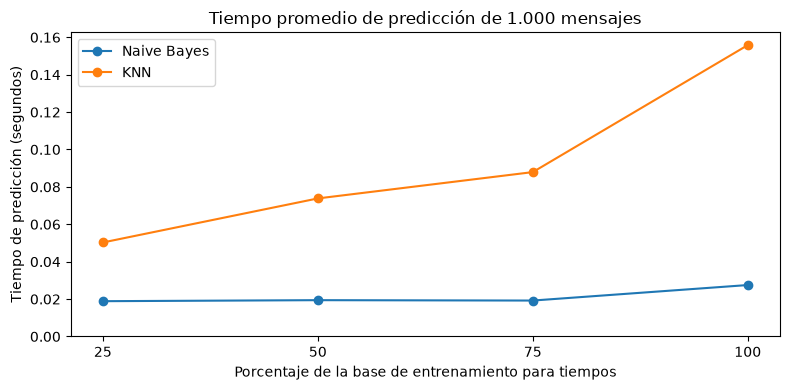

In [15]:
from sklearn.base import clone
from time import perf_counter

# El lote fijo pertenece a entrenamiento y queda fuera del ajuste de este experimento.
textos_base_tiempos, textos_lote_tiempos, etiquetas_base_tiempos, etiquetas_lote_tiempos = train_test_split(
    textos_entrenamiento, etiquetas_entrenamiento,
    test_size=1000, stratify=etiquetas_entrenamiento, random_state=SEMILLA,
)
assert textos_base_tiempos.index.intersection(textos_lote_tiempos.index).empty
assert textos_lote_tiempos.index.intersection(textos_prueba.index).empty
assert len(textos_lote_tiempos) == 1000
display(pd.Series({"Base de entrenamiento para tiempos": len(textos_base_tiempos),
                   "Lote fijo de predicción": len(textos_lote_tiempos)}, name="Mensajes").to_frame())

porcentajes_tiempos = [25, 50, 75, 100]
repeticiones_tiempos = 3
mediciones_tiempos = []
subconjuntos_tiempos = {}
for porcentaje in porcentajes_tiempos:
    cantidad = round(len(textos_base_tiempos) * porcentaje / 100)
    if porcentaje == 100:
        textos_subconjunto, etiquetas_subconjunto = textos_base_tiempos, etiquetas_base_tiempos
    else:
        textos_subconjunto, _, etiquetas_subconjunto, _ = train_test_split(
            textos_base_tiempos, etiquetas_base_tiempos,
            train_size=cantidad, stratify=etiquetas_base_tiempos, random_state=SEMILLA,
        )
    assert textos_subconjunto.index.intersection(textos_lote_tiempos.index).empty
    assert textos_subconjunto.index.intersection(textos_prueba.index).empty
    subconjuntos_tiempos[porcentaje] = textos_subconjunto.index
    modelos_tiempos = {
        "Naive Bayes": clone(modelo_nb_ajustado).fit(textos_subconjunto, etiquetas_subconjunto),
        "KNN": clone(modelo_knn_ajustado).fit(textos_subconjunto, etiquetas_subconjunto),
    }
    # Una llamada previa evita incluir el costo de la primera predicción en el promedio.
    for modelo in modelos_tiempos.values():
        modelo.predict(textos_lote_tiempos)
    for repeticion in range(repeticiones_tiempos):
        for nombre, modelo in modelos_tiempos.items():
            inicio = perf_counter()
            modelo.predict(textos_lote_tiempos)
            segundos = perf_counter() - inicio
            mediciones_tiempos.append({"Entrenamiento (%)": porcentaje, "Mensajes de entrenamiento": cantidad,
                                      "Modelo": nombre, "Repetición": repeticion + 1, "Segundos": segundos})

mediciones_tiempos = pd.DataFrame(mediciones_tiempos)
tabla_tiempos = (
    mediciones_tiempos.groupby(["Entrenamiento (%)", "Mensajes de entrenamiento", "Modelo"])["Segundos"]
    .mean().unstack("Modelo").reset_index()
    .rename(columns={"Naive Bayes": "Naive Bayes (s)", "KNN": "KNN (s)"})
    [["Entrenamiento (%)", "Mensajes de entrenamiento", "Naive Bayes (s)", "KNN (s)"]]
)
tabla_tiempos.columns.name = None
display(tabla_tiempos.round(6))

fig, ax = plt.subplots(figsize=(8, 4))
for nombre, columna in [("Naive Bayes", "Naive Bayes (s)"), ("KNN", "KNN (s)")]:
    ax.plot(tabla_tiempos["Entrenamiento (%)"], tabla_tiempos[columna], marker="o", label=nombre)
ax.set_title("Tiempo promedio de predicción de 1.000 mensajes")
ax.set_xlabel("Porcentaje de la base de entrenamiento para tiempos")
ax.set_ylabel("Tiempo de predicción (segundos)")
ax.set_xticks(porcentajes_tiempos)
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
plt.show()

El 100% corresponde a la base que queda después de reservar el lote de 1.000 mensajes, no a todos los históricos. Ambos modelos usan los mismos subconjuntos estratificados y las configuraciones seleccionadas por validación. Cada promedio incluye tres predicciones completas del pipeline, con transformación del texto y clasificación; excluye entrenamiento y búsqueda de parámetros. Los tiempos pueden variar entre ejecuciones y no representan una medición de producción.

Naive Bayes predijo más rápido en los cuatro tamaños y su tiempo se mantuvo aproximadamente estable. El tiempo de KNN creció al aumentar el entrenamiento porque compara cada consulta con más mensajes almacenados; Naive Bayes usa las probabilidades ya resumidas por clase y término. Para un volumen de 6.500 mensajes diarios, un menor costo de predicción deja más margen de procesamiento, aunque todavía faltan las mediciones y los criterios de un sistema real. Los tiempos favorecen a Naive Bayes en costo, pero por sí solos no justifican la elección final: también hay que considerar la calidad de la clasificación y el tratamiento de fraude.

## Parte E · Regla de derivación y evaluación (`src/derivacion.py`)

**Paso 13.** Implementen `derivar` y `evaluar_derivacion` hasta que pasen `tests/test_derivacion.py`.

In [16]:
pruebas_derivacion = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_derivacion.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_derivacion.stdout.strip())
assert np.isnan(evaluar_derivacion([], [])["cobertura"])
assert np.isnan(evaluar_derivacion(["fraude"], [REVISION])["exactitud_automatica"])
assert evaluar_derivacion(["fraude"], [REVISION])["fraude_perdido"] == 0
assert np.isnan(evaluar_derivacion(["tarjeta"], ["tarjeta"])["fraude_perdido"])
print("Sin denominador, el indicador se informa como NaN (no disponible).")

....                                                                     [100%]
4 passed in 0.29s
Sin denominador, el indicador se informa como NaN (no disponible).


La probabilidad de fraude tiene prioridad, aunque otra clase sea más probable. Luego se aplica la confianza y, si no alcanza, se deriva a revisión humana. Los indicadores sin denominador se informan como NaN: no se los reemplaza por una exactitud o un fraude perdido aparentes.

**Paso 14.** Probabilidades fuera de muestra con `cross_val_predict` y elección de los dos umbrales (con margen de seguridad) para Naive Bayes y para KNN.

In [17]:
from sklearn.model_selection import cross_val_predict

modelos_ajustados = {"Naive Bayes": modelo_nb_ajustado, "KNN": modelo_knn_ajustado}
clases_oof = np.unique(etiquetas_entrenamiento)
y_entrenamiento = etiquetas_entrenamiento.to_numpy()
manual_entrenamiento = df_original.loc[textos_entrenamiento.index, "equipo_derivado"].to_numpy()
# Fijados en Sprint 3: no hay nueva búsqueda ni ajuste de umbrales.
umbrales_congelados = {"Naive Bayes": (0.10, 0.60), "KNN": (0.10, 0.60)}

def contar_consecuencias(y_real, destino):
    y_real, destino = np.asarray(y_real), np.asarray(destino)
    automatico = destino != REVISION
    fraude_real = y_real == "fraude"
    perdido = fraude_real & automatico & (destino != "fraude")
    alerta_falsa = (~fraude_real) & (destino == "fraude")
    error = automatico & (destino != y_real)
    otros = error & (~perdido) & (~alerta_falsa)
    assert int(error.sum()) == int(perdido.sum() + alerta_falsa.sum() + otros.sum())
    return {
        "mensajes": len(y_real), "fraudes_reales": int(fraude_real.sum()),
        "no_fraudes": int((~fraude_real).sum()), "automaticos": int(automatico.sum()),
        "fraudes_mal_derivados": int(perdido.sum()), "falsas_alertas": int(alerta_falsa.sum()),
        "errores_automaticos": int(error.sum()), "otros_errores": int(otros.sum()),
        "revisiones": int((~automatico).sum()),
        "tasa_falsas_alertas": alerta_falsa.sum() / (~fraude_real).sum(),
        "tasa_revision": (~automatico).mean(), **evaluar_derivacion(y_real, destino),
    }

probabilidades_oof, destinos_oof, filas_oof = {}, {}, []
for nombre, modelo in modelos_ajustados.items():
    np.testing.assert_array_equal(modelo.classes_, clases_oof)
    proba = cross_val_predict(modelo, textos_entrenamiento, etiquetas_entrenamiento,
                             cv=particiones_cv, method="predict_proba", n_jobs=1)
    assert np.isfinite(proba).all()
    np.testing.assert_allclose(proba.sum(axis=1), 1, atol=1e-10)
    destino = derivar(proba, clases_oof, *umbrales_congelados[nombre])
    probabilidades_oof[nombre], destinos_oof[nombre] = proba, destino
    filas_oof.append({"Modelo": nombre, **contar_consecuencias(y_entrenamiento, destino)})
costos_oof = pd.DataFrame(filas_oof).set_index("Modelo")
columnas_costos = ["fraudes_mal_derivados", "falsas_alertas", "otros_errores", "errores_automaticos", "revisiones",
                  "tasa_falsas_alertas", "tasa_revision", "cobertura", "exactitud_automatica", "fraude_perdido"]
print(f"OOF: {len(y_entrenamiento)} mensajes; {int((y_entrenamiento == 'fraude').sum())} fraudes reales.")
display(costos_oof[columnas_costos].round(6))
print("Las tasas son proporciones de 0 a 1: fraude perdido / fraudes reales; alertas / no fraudes; revisión y cobertura / todos; exactitud / automáticos.")
tiempos_comparados = {nombre: float(tabla_tiempos.loc[tabla_tiempos["Entrenamiento (%)"].eq(100), f"{nombre} (s)"].iloc[0])
                     for nombre in modelos_ajustados}
# Supuesto explícito del ejercicio: escenario B, priorizar carga operativa y errores generales.
# No se crea un puntaje ni se equiparan los costos de errores de distinto tipo.
nb_oof, knn_oof = costos_oof.loc["Naive Bayes"], costos_oof.loc["KNN"]
ventajas_operativas_nb = all(nb_oof[c] < knn_oof[c] for c in ["falsas_alertas", "errores_automaticos", "revisiones"])
assert ventajas_operativas_nb and nb_oof["exactitud_automatica"] > knn_oof["exactitud_automatica"]
assert tiempos_comparados["Naive Bayes"] < tiempos_comparados["KNN"]
nombre_elegido = "Naive Bayes"
print("Recomendación provisional bajo escenario B:", nombre_elegido)
print("Si minimizar fraude perdido es la prioridad dominante (A), se favorece KNN; para equilibrar costos (C) falta acordar prioridades.")
categorias_disjuntas = ["fraudes_mal_derivados", "falsas_alertas", "otros_errores", "revisiones"]
delta_oof = (costos_oof.loc["KNN", categorias_disjuntas] - costos_oof.loc["Naive Bayes", categorias_disjuntas]).astype(int)
display(delta_oof.rename("Diferencia KNN menos NB (OOF)").to_frame())
print("Sensibilidad hipotética, sin costos monetarios de Cauce: ΔC = "
      + " + ".join(f"({int(delta_oof[c])}) × {peso}" for c,peso in zip(categorias_disjuntas, ["c_fraude", "c_alerta", "c_otro", "c_revision"])))
print("KNN se favorece si ΔC < 0; NB si ΔC > 0; empate si ΔC = 0. No se suma el total de errores a sus componentes.")


OOF: 6344 mensajes; 707 fraudes reales.


,fraudes_mal_derivados,falsas_alertas,otros_errores,errores_automaticos,revisiones,tasa_falsas_alertas,tasa_revision,cobertura,exactitud_automatica,fraude_perdido
Modelo,,,,,,,,,,
Naive Bayes,49,88,219,356,33,0.015611,0.005202,0.994798,0.943591,0.069307
KNN,27,340,126,493,201,0.060316,0.031683,0.968317,0.919746,0.038190


Las tasas son proporciones de 0 a 1: fraude perdido / fraudes reales; alertas / no fraudes; revisión y cobertura / todos; exactitud / automáticos.
Recomendación provisional bajo escenario B: Naive Bayes
Si minimizar fraude perdido es la prioridad dominante (A), se favorece KNN; para equilibrar costos (C) falta acordar prioridades.


,Diferencia KNN menos NB (OOF)
fraudes_mal_derivados,-22
falsas_alertas,252
otros_errores,-93
revisiones,168


Sensibilidad hipotética, sin costos monetarios de Cauce: ΔC = (-22) × c_fraude + (252) × c_alerta + (-93) × c_otro + (168) × c_revision
KNN se favorece si ΔC < 0; NB si ΔC > 0; empate si ΔC = 0. No se suma el total de errores a sus componentes.


Conservamos fraude `0.10` y confianza `0.60` para ambos modelos. En el Sprint 3 se eligieron con 56 pares sobre OOF, exigiendo mejora respecto de la mesa en cada partición y con los cuatro vecinos de grilla. Esa búsqueda permanece documentada en la entrega anterior; aquí no se repite. Tampoco se repiten búsquedas de hiperparámetros: los valores son los del Sprint 2.

Los costos OOF permiten comparar consecuencias. Para resolver el ejercicio asumimos el **escenario B**: reducir errores generales, avisos falsos y revisión con menor tiempo de predicción. Bajo ese supuesto recomendamos Naive Bayes. El **escenario A**, que prioriza perder menos fraudes, favorece KNN. El **escenario C** exige que Cauce acuerde riesgo tolerable y capacidad de atención; no hay un ganador único sin esas prioridades. La diferencia de costos relativos es hipotética: cada término tiene su propio peso y las cuatro categorías no se superponen.

La recomendación es provisional. OOF usa datos que ya participaron en la elección de hiperparámetros y umbrales, por lo que puede resultar optimista. Además, en Sprint 3 se consultó prueba para elegir KNN. Esta revisión reconoce ese antecedente: volver a describir la misma prueba no genera una confirmación independiente. Para eso hacen falta nuevos mensajes etiquetados. Las metas oficiales siguen pendientes.

**Paso 15.** Evaluación única en prueba: tabla con los cinco indicadores de aceptación para Naive Bayes, KNN y la mesa de entrada; reporte de clasificación y matriz de confusión del modelo elegido.

In [18]:
from sklearn.metrics import classification_report

# Los cinco indicadores son una propuesta descriptiva, sin metas oficiales confirmadas.
y_prueba = etiquetas_prueba.to_numpy()
manual_prueba = df_original.loc[textos_prueba.index, "equipo_derivado"].to_numpy()
predicciones_prueba = {}
destinos_prueba = {}
probabilidades_prueba = {}
filas_finales = []
for nombre, modelo in modelos_ajustados.items():
    proba = modelo.predict_proba(textos_prueba)
    predicho = modelo.classes_[proba.argmax(axis=1)]
    destino = derivar(proba, modelo.classes_, *umbrales_congelados[nombre])
    probabilidades_prueba[nombre], predicciones_prueba[nombre], destinos_prueba[nombre] = proba, predicho, destino
    filas_finales.append({"Modelo": nombre,
                         "accuracy": accuracy_score(y_prueba, predicho),
                         "f1_macro": f1_score(y_prueba, predicho, average="macro", zero_division=0),
                         **evaluar_derivacion(y_prueba, destino)})
filas_finales.append({"Modelo": "Mesa de entrada",
                     "accuracy": accuracy_score(y_prueba, manual_prueba),
                     "f1_macro": f1_score(y_prueba, manual_prueba, average="macro", zero_division=0),
                     **evaluar_derivacion(y_prueba, manual_prueba)})
tabla_final = pd.DataFrame(filas_finales).set_index("Modelo")
tabla_final_visible = tabla_final.copy()
for columna in ["accuracy", "cobertura", "exactitud_automatica", "fraude_perdido"]:
    tabla_final_visible[columna] *= 100
tabla_final_visible = tabla_final_visible.rename(columns={
    "accuracy": "Accuracy (%)", "f1_macro": "F1 macro", "cobertura": "Cobertura (%)",
    "exactitud_automatica": "Exactitud automática (%)", "fraude_perdido": "Fraude perdido (%)",
})
print(f"Evaluación final: los mismos {len(y_prueba)} mensajes aptos para los tres métodos.")
display(tabla_final_visible.round(4))
print("En la mesa, cobertura y exactitud automática equivalentes comparan destinos manuales ya realizados.")

# La elección ya quedó declarada con OOF y el escenario B en el paso 14.
filas_costos_prueba = [{"Modelo": nombre, **contar_consecuencias(y_prueba, destino)}
                     for nombre, destino in destinos_prueba.items()]
costos_prueba = pd.DataFrame(filas_costos_prueba).set_index("Modelo")
display(costos_prueba[columnas_costos].round(6))
especificaciones = [
    ("Accuracy", "accuracy", "tasa", "Clase predicha correcta / todos los mensajes; mayor es mejor."),
    ("F1 macro", "f1_macro", "f1", "Promedio entre clases; mayor es mejor."),
    ("Cobertura", "cobertura", "tasa", "Automáticos / todos; interpretar junto con exactitud."),
    ("Exactitud automática", "exactitud_automatica", "tasa", "Correctos / automáticos; mayor es mejor."),
    ("Fraude perdido", "fraude_perdido", "tasa", "Mal derivados / fraudes reales; menor es mejor."),
    ("Fraudes mal derivados", "fraudes_mal_derivados", "cantidad", "Fraudes automáticos a otro sector; menor es mejor."),
    ("Falsas alertas de fraude", "falsas_alertas", "cantidad", "No fraudes enviados a Fraude; menor carga es mejor."),
    ("Tasa de falsas alertas", "tasa_falsas_alertas", "tasa", "Alertas falsas / no fraudes; menor es mejor."),
    ("Errores automáticos totales", "errores_automaticos", "cantidad", "Incluye fraude perdido, alertas falsas y otros errores."),
    ("Otros errores automáticos", "otros_errores", "cantidad", "Excluye fraude perdido y alertas falsas; menor es mejor."),
    ("Mensajes enviados a revisión", "revisiones", "cantidad", "Requieren intervención humana; menor carga es mejor."),
    ("Tasa de revisión", "tasa_revision", "tasa", "Revisiones / todos los mensajes; menor carga es mejor."),
    ("Tiempo de predicción (1.000 mensajes)", "tiempo", "tiempo", "Promedio de tres repeticiones del paso 12 al 100%; menor es mejor."),
]
filas_comparacion = []
for indicador, clave, tipo, interpretacion in especificaciones:
    valores = [tiempos_comparados[m] if clave == "tiempo" else
               (tabla_final.loc[m, clave] if clave in tabla_final.columns else costos_prueba.loc[m, clave])
               for m in ["Naive Bayes", "KNN"]]
    nb, knn = valores
    diferencia = knn - nb
    if tipo == "tasa":
        visibles = [f"{100*v:.2f}%" for v in valores]; delta = f"{100*diferencia:+.2f} pp"
    elif tipo == "f1":
        visibles = [f"{v:.4f}" for v in valores]; delta = f"{diferencia:+.4f}"
    elif tipo == "tiempo":
        visibles = [f"{v:.4f} s" for v in valores]; delta = f"{diferencia:+.4f} s"
    else:
        visibles = [str(int(v)) for v in valores]; delta = f"{int(diferencia):+d}"
    filas_comparacion.append([indicador, *visibles, delta, interpretacion])
comparacion_completa = pd.DataFrame(filas_comparacion, columns=["Indicador", "Naive Bayes", "KNN", "Diferencia", "Interpretación"])
print("Diferencia = KNN menos Naive Bayes; pp = puntos porcentuales.")
display(comparacion_completa.style.set_properties(**{"white-space": "normal", "max-width": "310px", "text-align": "left"}))
delta_prueba = (costos_prueba.loc["KNN", categorias_disjuntas] - costos_prueba.loc["Naive Bayes", categorias_disjuntas]).astype(int)
print("Descomposición de costos en prueba (sólo descripción, no selección):", delta_prueba.to_dict())
print("Los tiempos miden predicción de pipelines en este equipo, no atención al cliente ni rendimiento en producción.")
modelo_elegido = modelos_ajustados[nombre_elegido]
umbrales_elegidos = umbrales_congelados[nombre_elegido]
destino_elegido_prueba = destinos_prueba[nombre_elegido]
predicho_elegido_prueba = predicciones_prueba[nombre_elegido]
print("Modelo elegido para resolver el ejercicio:", nombre_elegido)
print("Umbrales mantenidos desde OOF:", umbrales_elegidos)
reporte_dict = classification_report(y_prueba, predicho_elegido_prueba, labels=clases, output_dict=True, zero_division=0)
reporte_clasificacion = pd.DataFrame.from_dict({k: v for k, v in reporte_dict.items() if isinstance(v, dict)}, orient="index")
display(reporte_clasificacion.rename(columns={"precision": "Precision", "recall": "Recall", "f1-score": "F1", "support": "Mensajes"}).round(4))
matriz_elegida = pd.DataFrame(
    confusion_matrix(y_prueba, predicho_elegido_prueba, labels=clases),
    index=pd.Index(clases, name="Equipo real"), columns=pd.Index(clases, name="Equipo predicho"),
)
display(matriz_elegida)
display((100 * matriz_elegida.div(matriz_elegida.sum(axis=1), axis=0)).round(2))
mascara_error_automatico = (destino_elegido_prueba != REVISION) & (destino_elegido_prueba != y_prueba)
indices_errores = textos_prueba.index[mascara_error_automatico].sort_values()[:10]
print("Errores de derivación automática disponibles:", int(mascara_error_automatico.sum()))
print("Criterios de aceptación pendientes de confirmación; no se declara aptitud para producción.")

Evaluación final: los mismos 1586 mensajes aptos para los tres métodos.


,Accuracy (%),F1 macro,Cobertura (%),Exactitud automática (%),Fraude perdido (%)
Modelo,,,,,
Naive Bayes,93.8840,0.9346,99.4956,94.1698,5.1136
KNN,92.8121,0.9260,96.1538,92.6557,3.4091
Mesa de entrada,83.5435,0.8237,100.0000,83.5435,33.5227


En la mesa, cobertura y exactitud automática equivalentes comparan destinos manuales ya realizados.


,fraudes_mal_derivados,falsas_alertas,otros_errores,errores_automaticos,revisiones,tasa_falsas_alertas,tasa_revision,cobertura,exactitud_automatica,fraude_perdido
Modelo,,,,,,,,,,
Naive Bayes,9,16,67,92,8,0.011348,0.005044,0.994956,0.941698,0.051136
KNN,6,75,31,112,61,0.053191,0.038462,0.961538,0.926557,0.034091


Diferencia = KNN menos Naive Bayes; pp = puntos porcentuales.


...

Descomposición de costos en prueba (sólo descripción, no selección): {'fraudes_mal_derivados': -3, 'falsas_alertas': 59, 'otros_errores': -36, 'revisiones': 53}
Los tiempos miden predicción de pipelines en este equipo, no atención al cliente ni rendimiento en producción.
Modelo elegido para resolver el ejercicio: Naive Bayes
Umbrales mantenidos desde OOF: (0.1, 0.6)


,Precision,Recall,F1,Mensajes
cuenta_acceso,0.9266,0.9528,0.9395,318.0
fraude,0.9368,0.9261,0.9314,176.0
prestamos_inversiones,0.8774,0.9394,0.9073,198.0
tarjeta,0.9451,0.9475,0.9463,400.0
transferencias,0.9703,0.9271,0.9482,494.0
macro avg,0.9312,0.9386,0.9346,1586.0
weighted avg,0.9399,0.9388,0.9390,1586.0


Equipo predicho,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,303,1,5,8,1
fraude,2,163,2,5,4
prestamos_inversiones,4,2,186,3,3
tarjeta,9,1,5,379,6
transferencias,9,7,14,6,458


Equipo predicho,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,95.28,0.31,1.57,2.52,0.31
fraude,1.14,92.61,1.14,2.84,2.27
prestamos_inversiones,2.02,1.01,93.94,1.52,1.52
tarjeta,2.25,0.25,1.25,94.75,1.50
transferencias,1.82,1.42,2.83,1.21,92.71


Errores de derivación automática disponibles: 92
Criterios de aceptación pendientes de confirmación; no se declara aptitud para producción.


Accuracy y F1 describen la clasificación directa; las otras métricas describen destinos después de la regla. Los tres métodos usan los mismos 1.586 mensajes aptos; cobertura manual significa que ya existe una decisión. Fraude perdido divide por 176 fraudes reales y falsas alertas por 1.410 no fraudes. Exactitud automática divide por los destinos automáticos de cada modelo. Los cortos quedan fuera de esta prueba.

KNN pierde tres fraudes menos que Naive Bayes, pero genera 59 alertas falsas, 20 errores automáticos y 53 revisiones adicionales. Otros errores automáticos disminuyen en 36: por eso no hay que sumar el total a sus componentes ni asumir igual costo para todas las fallas. La cobertura más alta sólo aporta si los destinos son correctos. Los tiempos del paso 12 ayudan a comparar algoritmos: KNN busca vecinos y Naive Bayes usa probabilidades aprendidas; no miden atención al cliente.

La recomendación de Naive Bayes viene del análisis OOF y del supuesto operativo B, declarado antes de esta descripción. En Sprint 3 sí se utilizó esta prueba para elegir KNN: no presentamos la revisión como independiente de prueba ni ajustamos parámetros para mejorar sus resultados. Se necesitan nuevos datos etiquetados y prioridades confirmadas para validar la elección.

**Paso 16.** Análisis de 10 errores de derivación automática: causa de cada uno y una mejora concreta.

In [19]:
# Descripciones anonimizadas de diez errores reales; no son transcripciones de clientes.
analisis_errores = [('tarjeta', 'prestamos_inversiones', 'Consulta por tarjeta virtual y refinanciación de un préstamo.', 'Las dos intenciones compiten y domina el vocabulario del préstamo.', 'Acordar la intención principal y sumar ejemplos con consultas múltiples.'), ('cuenta_acceso', 'tarjeta', 'Informa que la aplicación no funciona, sin detallar la dificultad.', 'El contexto es insuficiente para distinguir acceso de problemas con tarjeta.', 'Agregar ejemplos de fallas de la aplicación y pedir precisar qué operación falla.'), ('fraude', 'prestamos_inversiones', 'Pide contacto y una solución urgente sin explicar el motivo.', 'No hay vocabulario que identifique fraude; la urgencia por sí sola no alcanza.', 'Solicitar contexto y evaluar en validación cómo revisar consultas genéricas.'), ('transferencias', 'prestamos_inversiones', 'Pide contacto y comenta que actualizó la aplicación.', 'No describe una transferencia; predominan expresiones genéricas.', 'Incorporar ejemplos con poco contexto y acordar cuándo pedir aclaración.'), ('tarjeta', 'cuenta_acceso', 'Solicita ayuda sin indicar producto ni operación.', 'La categoría real no se puede inferir claramente del contenido disponible.', 'Revisar el criterio de anotación y solicitar el producto afectado.'), ('transferencias', 'fraude', 'Menciona un problema de cuenta con escritura informal.', 'Hay poco contexto y variaciones ortográficas; se activa la prioridad de fraude.', 'Sumar escritura informal y casos de problemas operativos sin fraude.'), ('cuenta_acceso', 'prestamos_inversiones', 'Solicita una llamada y dice que ya escribió antes.', 'El pedido de contacto no explica el problema de acceso.', 'Pedir contexto y evaluar la revisión de reclamos genéricos con entrenamiento.'), ('transferencias', 'cuenta_acceso', 'Combina un comprobante que no descarga con una cuenta bloqueada.', 'La intención de acceso domina sobre la dificultad con el comprobante.', 'Acordar prioridades para consultas múltiples y agregar ejemplos de comprobantes.'), ('tarjeta', 'fraude', 'Reclama un cobro extraño y comenta que reinició el celular.', 'Un cobro extraño puede ser un reclamo de tarjeta o una operación desconocida.', 'Revisar la anotación y aclarar si se desconoce la operación.'), ('prestamos_inversiones', 'fraude', 'Denuncia ingreso sin permiso y cambio de contraseña.', 'Posible inconsistencia: el texto sugiere fraude, pero su referencia es préstamos.', 'Consultar la anotación con el responsable sin alterar la etiqueta de la entrega.')]
filas_errores = []
for numero, (indice, analisis) in enumerate(zip(indices_errores, analisis_errores), 1):
    real, asignado, resumen, causa, mejora = analisis
    posicion = textos_prueba.index.get_loc(indice)
    assert y_prueba[posicion] == real and destino_elegido_prueba[posicion] == asignado
    assert destino_elegido_prueba[posicion] != REVISION and asignado != real
    filas_errores.append({"Caso": numero, "Categoría real": real, "Destino asignado": asignado,
                         "Descripción anonimizada": resumen, "Posible causa": causa, "Mejora propuesta": mejora})
tabla_errores = pd.DataFrame(filas_errores)
assert len(tabla_errores) == min(10, int(mascara_error_automatico.sum()))
display(tabla_errores[["Caso", "Categoría real", "Destino asignado", "Descripción anonimizada"]].style.set_properties(
    **{"white-space": "normal", "max-width": "240px", "text-align": "left"}))
display(tabla_errores[["Caso", "Posible causa", "Mejora propuesta"]].style.set_properties(
    **{"white-space": "normal", "max-width": "340px", "text-align": "left"}))
print("Se describen errores automáticos reales; sus posibles causas no son una atribución causal comprobada.")
print("Las mejoras se proponen para una revisión futura y no se implementan ni reajustan con prueba.")

,Caso,Categoría real,Destino asignado,Descripción anonimizada
0,1,tarjeta,prestamos_inversiones,Consulta por tarjeta virtual y refinanciación de un préstamo.
1,2,cuenta_acceso,tarjeta,"Informa que la aplicación no funciona, sin detallar la dificultad."
2,3,fraude,prestamos_inversiones,Pide contacto y una solución urgente sin explicar el motivo.
3,4,transferencias,prestamos_inversiones,Pide contacto y comenta que actualizó la aplicación.
4,5,tarjeta,cuenta_acceso,Solicita ayuda sin indicar producto ni operación.
5,6,transferencias,fraude,Menciona un problema de cuenta con escritura informal.
6,7,cuenta_acceso,prestamos_inversiones,Solicita una llamada y dice que ya escribió antes.
7,8,transferencias,cuenta_acceso,Combina un comprobante que no descarga con una cuenta bloqueada.
8,9,tarjeta,fraude,Reclama un cobro extraño y comenta que reinició el celular.
9,10,prestamos_inversiones,fraude,Denuncia ingreso sin permiso y cambio de contraseña.


,Caso,Posible causa,Mejora propuesta
0,1,Las dos intenciones compiten y domina el vocabulario del préstamo.,Acordar la intención principal y sumar ejemplos con consultas múltiples.
1,2,El contexto es insuficiente para distinguir acceso de problemas con tarjeta.,Agregar ejemplos de fallas de la aplicación y pedir precisar qué operación falla.
2,3,No hay vocabulario que identifique fraude; la urgencia por sí sola no alcanza.,Solicitar contexto y evaluar en validación cómo revisar consultas genéricas.
3,4,No describe una transferencia; predominan expresiones genéricas.,Incorporar ejemplos con poco contexto y acordar cuándo pedir aclaración.
4,5,La categoría real no se puede inferir claramente del contenido disponible.,Revisar el criterio de anotación y solicitar el producto afectado.
5,6,Hay poco contexto y variaciones ortográficas; se activa la prioridad de fraude.,Sumar escritura informal y casos de problemas operativos sin fraude.
6,7,El pedido de contacto no explica el problema de acceso.,Pedir contexto y evaluar la revisión de reclamos genéricos con entrenamiento.
7,8,La intención de acceso domina sobre la dificultad con el comprobante.,Acordar prioridades para consultas múltiples y agregar ejemplos de comprobantes.
8,9,Un cobro extraño puede ser un reclamo de tarjeta o una operación desconocida.,Revisar la anotación y aclarar si se desconoce la operación.
9,10,"Posible inconsistencia: el texto sugiere fraude, pero su referencia es préstamos.",Consultar la anotación con el responsable sin alterar la etiqueta de la entrega.


Se describen errores automáticos reales; sus posibles causas no son una atribución causal comprobada.
Las mejoras se proponen para una revisión futura y no se implementan ni reajustan con prueba.


Analizamos los primeros diez errores automáticos de Naive Bayes en el orden original. Los resúmenes omiten nombres, identificadores y detalles financieros. Aparecen intenciones múltiples y pedidos sin contexto; un caso de fraude se perdió porque no describe su problema. El último caso sugiere una inconsistencia de anotación: conservamos su etiqueta y proponemos revisarla. Las mejoras son propuestas futuras, sin ajustes sobre prueba.

**Paso 17.** Impacto en un día de 6.500 mensajes.

In [20]:
volumen_diario = 6500
proporcion_cortos = len(df_revision) / len(df_preparado)
aptos_por_dia = volumen_diario * (1 - proporcion_cortos)
cortos_por_dia = volumen_diario * proporcion_cortos
proyecciones = {}
for nombre in modelos_ajustados:
    costos = costos_prueba.loc[nombre]
    factor = aptos_por_dia / len(y_prueba)
    proyecciones[nombre] = {
        "Automáticos": factor * costos["automaticos"],
        "Revisión por incertidumbre (aptos)": factor * costos["revisiones"],
        "Revisión por mensajes cortos": cortos_por_dia,
        "Revisión humana total": factor * costos["revisiones"] + cortos_por_dia,
        "Automáticos correctos": factor * (costos["automaticos"] - costos["errores_automaticos"]),
        "Automáticos incorrectos": factor * costos["errores_automaticos"],
        "Fraudes enviados a otro equipo": factor * costos["fraudes_mal_derivados"],
        "Falsas alertas de fraude": factor * costos["falsas_alertas"],
    }
    np.testing.assert_allclose(proyecciones[nombre]["Automáticos"] + proyecciones[nombre]["Revisión humana total"], volumen_diario)
proyecciones_diarias = pd.DataFrame(proyecciones)
proyeccion_diaria = proyecciones_diarias[nombre_elegido]
display(proyecciones_diarias.round(1))
costos_manual = contar_consecuencias(y_prueba, manual_prueba)
comparacion_diaria = pd.DataFrame({
    **{m: [proyecciones[m]["Automáticos incorrectos"], proyecciones[m]["Fraudes enviados a otro equipo"], proyecciones[m]["Falsas alertas de fraude"]] for m in modelos_ajustados},
    "Mesa en mensajes aptos": [aptos_por_dia * costos_manual[c] / len(y_prueba)
                              for c in ["errores_automaticos", "fraudes_mal_derivados", "falsas_alertas"]],
}, index=["Derivaciones incorrectas", "Fraudes enviados a otro equipo", "Falsas alertas de fraude"])
display(comparacion_diaria.round(1))
print("Proyección descriptiva de tasas de prueba: no son mediciones diarias ni métricas OOF. No se conoce el resultado posterior de las revisiones.")


,Naive Bayes,KNN
Automáticos,6410.6,6195.3
Revisión por incertidumbre (aptos),32.5,247.8
Revisión por mensajes cortos,56.9,56.9
Revisión humana total,89.4,304.7
Automáticos correctos,6036.9,5740.3
Automáticos incorrectos,373.8,455.0
Fraudes enviados a otro equipo,36.6,24.4
Falsas alertas de fraude,65.0,304.7


,Naive Bayes,KNN,Mesa en mensajes aptos
Derivaciones incorrectas,373.8,455.0,1060.3
Fraudes enviados a otro equipo,36.6,24.4,239.7
Falsas alertas de fraude,65.0,304.7,170.6


Proyección descriptiva de tasas de prueba: no son mediciones diarias ni métricas OOF. No se conoce el resultado posterior de las revisiones.


La proyección separa 70/8.000 mensajes cortos: unos 56,9 por día requieren revisión. Sobre los 6.443,1 aptos se aplican las proporciones de cada modelo en prueba; los cortos se suman una sola vez. Se muestran ambos modelos, incluidas alertas falsas y revisiones. La comparación manual usa esa misma fracción apta. Son valores esperados si la distribución se mantiene, no un día observado; fraude perdido divide por todos los aptos para proyectar su cantidad, sin confundirlo con su porcentaje sobre los fraudes reales.

## Parte F · Predicción de los mensajes nuevos

**Paso 18.** Reentrenen el modelo elegido con todos los mensajes históricos limpios y apliquen la regla a `datos/mensajes_nuevos.csv`.

In [21]:
modelo_final = clone(modelo_elegido).fit(df_entrenamiento["texto_limpio"], df_entrenamiento["equipo_final"])
df_nuevos = pd.read_csv("datos/mensajes_nuevos.csv")
assert len(df_nuevos) == 2040
textos_nuevos_limpios = df_nuevos["texto"].map(limpiar_texto)
mascara_cortos_nuevos = textos_nuevos_limpios.str.split().str.len().lt(2)
proba_nuevos = modelo_final.predict_proba(textos_nuevos_limpios)
predicho_nuevos = modelo_final.classes_[proba_nuevos.argmax(axis=1)]
prob_max_nuevos = proba_nuevos.max(axis=1)
posicion_fraude_final = np.flatnonzero(modelo_final.classes_ == "fraude")[0]
prob_fraude_nuevos = proba_nuevos[:, posicion_fraude_final]
destino_nuevos = derivar(proba_nuevos, modelo_final.classes_, *umbrales_elegidos)
destino_nuevos[mascara_cortos_nuevos.to_numpy()] = REVISION
display(pd.Series({
    "Históricos aptos usados en el ajuste final": len(df_entrenamiento),
    "Mensajes nuevos": len(df_nuevos),
    "Mensajes nuevos cortos": mascara_cortos_nuevos.sum(),
    "Nuevos derivados automáticamente": np.sum(destino_nuevos != REVISION),
    "Nuevos enviados a revisión humana": np.sum(destino_nuevos == REVISION),
}, name="Cantidad").to_frame())
display(pd.Series(destino_nuevos).value_counts().to_frame("Destinos nuevos"))

,Cantidad
Históricos aptos usados en el ajuste final,7930
Mensajes nuevos,2040
Mensajes nuevos cortos,15
Nuevos derivados automáticamente,2007
Nuevos enviados a revisión humana,33


,Destinos nuevos
transferencias,632
tarjeta,442
cuenta_acceso,409
prestamos_inversiones,266
fraude,258
revision_humana,33


Se reajusta la configuración elegida con todos los históricos aptos, incluida la antigua partición de prueba, sólo después de cerrar la evaluación. Los umbrales permanecen iguales. Conservamos predicciones y probabilidades también en mensajes cortos para respetar las columnas de entrega, pero forzamos su destino a revisión humana: esas probabilidades no bastan para automatizar un texto vacío o sin contexto.

**Paso 19.** Generen `predicciones_caso1.csv` (2.040 filas; columnas `id_mensaje`, `equipo_predicho`, `prob_max`, `prob_fraude`, `derivacion`) y verifiquen el formato.

In [22]:
from pathlib import Path

columnas_predicciones = ["id_mensaje", "equipo_predicho", "prob_max", "prob_fraude", "derivacion"]
predicciones_nuevos = pd.DataFrame({
    "id_mensaje": df_nuevos["id_mensaje"], "equipo_predicho": predicho_nuevos,
    "prob_max": prob_max_nuevos, "prob_fraude": prob_fraude_nuevos, "derivacion": destino_nuevos,
})
assert predicciones_nuevos.columns.tolist() == columnas_predicciones
assert len(predicciones_nuevos) == 2040
np.testing.assert_array_equal(predicciones_nuevos["id_mensaje"], df_nuevos["id_mensaje"])
assert predicciones_nuevos["id_mensaje"].duplicated().sum() == df_nuevos["id_mensaje"].duplicated().sum()
assert np.isfinite(proba_nuevos).all() and ((proba_nuevos >= 0) & (proba_nuevos <= 1)).all()
np.testing.assert_allclose(proba_nuevos.sum(axis=1), 1, atol=1e-10)
assert set(predicho_nuevos).issubset(set(modelo_final.classes_))
assert set(destino_nuevos).issubset(set(modelo_final.classes_) | {REVISION})
np.testing.assert_array_equal(predicho_nuevos, modelo_final.classes_[proba_nuevos.argmax(axis=1)])
np.testing.assert_allclose(prob_max_nuevos, proba_nuevos.max(axis=1))
np.testing.assert_allclose(prob_fraude_nuevos, proba_nuevos[:, posicion_fraude_final])
destinos_esperados = derivar(proba_nuevos, modelo_final.classes_, *umbrales_elegidos)
destinos_esperados[mascara_cortos_nuevos.to_numpy()] = REVISION
np.testing.assert_array_equal(destino_nuevos, destinos_esperados)
assert (destino_nuevos[mascara_cortos_nuevos.to_numpy()] == REVISION).all()
ruta_predicciones = Path("predicciones_caso1.csv")
predicciones_nuevos.to_csv(ruta_predicciones, index=False, encoding="utf-8")
predicciones_leidas = pd.read_csv(ruta_predicciones)
assert predicciones_leidas.columns.tolist() == columnas_predicciones and len(predicciones_leidas) == 2040
np.testing.assert_array_equal(predicciones_leidas["id_mensaje"], df_nuevos["id_mensaje"])
np.testing.assert_allclose(predicciones_leidas[["prob_max", "prob_fraude"]], predicciones_nuevos[["prob_max", "prob_fraude"]], atol=1e-12)
print("CSV UTF-8 validado: 2.040 filas, cinco columnas y una fila por mensaje original.")
print("Se conserva localmente porque incluye identificadores de mensajes.")

CSV UTF-8 validado: 2.040 filas, cinco columnas y una fila por mensaje original.
Se conserva localmente porque incluye identificadores de mensajes.


El archivo conserva el orden y los identificadores recibidos. No se quitaron duplicados de los mensajes nuevos. Sólo se muestran agregados en el notebook; el CSV con identificadores queda fuera del repositorio público.

## Parte G · Informe ejecutivo

**Paso 20.** El informe para Laura Benítez se entrega aparte, en `informe_ejecutivo.pdf`.

In [23]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak

estilos_pdf = getSampleStyleSheet()
estilos_pdf.add(ParagraphStyle("TextoCauce", fontName="Helvetica", fontSize=10.5, leading=15, spaceAfter=8))
estilos_pdf.add(ParagraphStyle("TituloCauce", fontName="Helvetica-Bold", fontSize=22, leading=27, spaceAfter=15))
estilos_pdf.add(ParagraphStyle("SeccionCauce", fontName="Helvetica-Bold", fontSize=13, leading=17, spaceBefore=12, spaceAfter=8))
estilos_pdf.add(ParagraphStyle("TablaCauce", fontName="Helvetica", fontSize=9, leading=12))
estilos_pdf.add(ParagraphStyle("NotaCauce", fontName="Helvetica", fontSize=9, leading=13, textColor=colors.HexColor("#444444"), spaceAfter=8))
contenido_pdf = []

def agregar_parrafo(texto, estilo="TextoCauce"):
    contenido_pdf.append(Paragraph(texto, estilos_pdf[estilo]))

def agregar_tabla(datos, anchos):
    celdas = [[Paragraph(str(valor), estilos_pdf["TablaCauce"]) for valor in fila] for fila in datos]
    tabla = Table(celdas, colWidths=anchos, repeatRows=1, hAlign="LEFT")
    tabla.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#edf1f4")),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 8), ("RIGHTPADDING", (0, 0), (-1, -1), 8),
        ("TOPPADDING", (0, 0), (-1, -1), 7), ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
        ("LINEBELOW", (0, 0), (-1, 0), 0.7, colors.HexColor("#80909b")),
        ("LINEBELOW", (0, 1), (-1, -1), 0.25, colors.HexColor("#d9dfe3")),
    ]))
    contenido_pdf.extend([tabla, Spacer(1, 8)])

def porcentaje_pdf(valor):
    return f"{100 * valor:.2f}%".replace(".", ",")

def numero_pdf(valor, decimales=0):
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

agregar_parrafo("Clasificación de mensajes - Cauce", "TituloCauce")
agregar_parrafo("Para Laura Benítez<br/>Andruszyszyn Emanuel - Quirós Juan<br/>14 de octubre de 2026", "NotaCauce")
agregar_parrafo("Problema y propuesta", "SeccionCauce")
agregar_parrafo("Cauce recibe unos 6.500 mensajes diarios y nueve personas los derivan. Un destino incorrecto demora la atención; en fraude puede impedir que se frene una operación sospechosa. Comparamos Naive Bayes con KNN para predecir el equipo a partir del texto.")
agregar_parrafo("La regla prioriza fraude si su probabilidad alcanza 0,10, automatiza los otros destinos con confianza de al menos 0,60 y envía el resto a revisión. Los textos con menos de dos palabras siempre requieren revisión. Conservamos los parámetros del Sprint 2 y los umbrales del Sprint 3.")
agregar_parrafo("Resultados descriptivos en prueba", "SeccionCauce")
agregar_parrafo(f"Ambos modelos y la mesa se comparan sobre {numero_pdf(len(y_prueba))} mensajes aptos, incluidos {numero_pdf(np.sum(y_prueba == 'fraude'))} fraudes reales. Esta prueba ya se había consultado para elegir KNN en Sprint 3.", "NotaCauce")
agregar_tabla([["Indicador", "Naive Bayes", "KNN", "Mesa"]] + [
    [etiqueta] + [(numero_pdf(tabla_final.loc[m, clave], 4) if clave == "f1_macro" else porcentaje_pdf(tabla_final.loc[m, clave])) for m in ["Naive Bayes", "KNN", "Mesa de entrada"]]
    for etiqueta, clave in [("Accuracy", "accuracy"), ("F1 macro", "f1_macro"), ("Cobertura", "cobertura"), ("Exactitud de derivación", "exactitud_automatica"), ("Fraude perdido", "fraude_perdido")]
] + [
    [etiqueta, numero_pdf(costos_prueba.loc["Naive Bayes", clave]), numero_pdf(costos_prueba.loc["KNN", clave]), numero_pdf(costos_manual[clave])]
    for etiqueta, clave in [("Fraudes mal derivados", "fraudes_mal_derivados"), ("Falsas alertas de fraude", "falsas_alertas"), ("Errores automáticos totales", "errores_automaticos"), ("Revisiones", "revisiones")]
], [235, 86, 86, 86])
agregar_parrafo("Accuracy y F1 miden clases predichas. Cobertura divide por todos los mensajes; exactitud, por los automáticos; fraude perdido, por los fraudes reales. La mesa tiene destinos manuales ya realizados: su cobertura no significa automatización. Revisión no cuenta como fraude perdido.", "NotaCauce")
agregar_parrafo(f"Recomendamos provisionalmente {nombre_elegido} bajo el supuesto de reducir errores generales y carga operativa. KNN pierde {abs(int(delta_prueba['fraudes_mal_derivados']))} fraudes menos, pero suma {int(delta_prueba['falsas_alertas'])} alertas falsas, {int(costos_prueba.loc['KNN','errores_automaticos']-costos_prueba.loc['Naive Bayes','errores_automaticos'])} errores automáticos y {int(delta_prueba['revisiones'])} revisiones. No hay una alternativa superior en todos los criterios.")

contenido_pdf.append(PageBreak())
agregar_parrafo("Costos y elección provisional", "TituloCauce")
agregar_parrafo(f"Revisamos probabilidades OOF sobre {numero_pdf(len(y_entrenamiento))} mensajes de entrenamiento, con {numero_pdf(np.sum(y_entrenamiento == 'fraude'))} fraudes reales. Cada predicción proviene de una partición que no ajustó ese ejemplo. No se cambiaron configuraciones ni umbrales.")
agregar_tabla([["Resultado OOF", "Naive Bayes", "KNN"]] + [
    [etiqueta] + [numero_pdf(costos_oof.loc[m, clave]) for m in modelos_ajustados]
    for etiqueta,clave in [("Fraudes mal derivados", "fraudes_mal_derivados"), ("Falsas alertas de fraude", "falsas_alertas"), ("Otros errores automáticos", "otros_errores"), ("Errores automáticos totales", "errores_automaticos"), ("Revisiones", "revisiones")]
] + [
    [etiqueta] + [porcentaje_pdf(costos_oof.loc[m, clave]) for m in modelos_ajustados]
    for etiqueta,clave in [("Cobertura", "cobertura"), ("Exactitud automática", "exactitud_automatica"), ("Fraude perdido", "fraude_perdido")]
], [291, 101, 101])
agregar_parrafo("A. Priorizar fraude: KNN pierde menos fraudes; conviene si esa reducción justifica más alertas falsas, revisiones y tiempo. Un fraude desviado y una alerta falsa tienen consecuencias distintas.")
agregar_parrafo("B. Reducir carga operativa: Naive Bayes tiene menos alertas falsas, errores automáticos y revisiones, y mayor exactitud automática. Es el supuesto elegido para esta entrega; aceptamos provisionalmente su mayor fraude perdido.")
agregar_parrafo("C. Equilibrar riesgo y capacidad: Cauce debe confirmar cuánto fraude tolera y qué volumen pueden atender Fraude y revisión. No conocemos costos económicos reales ni inventamos valores monetarios.")
agregar_parrafo("Sensibilidad hipotética sin doble conteo: la diferencia de costo KNN menos NB en OOF es "
    + " + ".join(f"({int(delta_oof[c])}) × {peso}" for c,peso in zip(categorias_disjuntas, ["c_fraude", "c_alerta", "c_otro", "c_revisión"]))
    + ". Cada peso corresponde a una categoría distinta. KNN se favorece si el resultado es negativo; NB si es positivo. El total de errores ya contiene las tres clases de error y no se suma otra vez.", "NotaCauce")
agregar_parrafo(f"En el lote de 1.000 mensajes del paso 12 al mayor tamaño, la predicción media fue {numero_pdf(tiempos_comparados['Naive Bayes'], 4)} s para NB y {numero_pdf(tiempos_comparados['KNN'], 4)} s para KNN. KNN busca vecinos; NB usa probabilidades aprendidas. Son tiempos de este equipo, no de atención al cliente ni de producción.", "NotaCauce")
agregar_parrafo("Los datos OOF ya participaron en la elección de parámetros y umbrales; pueden ser optimistas. Además, la prueba se consultó en la selección anterior. Esta revisión no es una confirmación independiente: se necesitan nuevos mensajes etiquetados.", "NotaCauce")

contenido_pdf.append(PageBreak())
agregar_parrafo("Proyección y entrega", "TituloCauce")
agregar_parrafo(f"Para 6.500 mensajes diarios usamos la proporción de cortos {len(df_revision)}/{len(df_preparado)}: {numero_pdf(cortos_por_dia, 1)} cortos y {numero_pdf(aptos_por_dia, 1)} aptos. A los aptos se aplican tasas de prueba; los cortos se suman una sola vez a revisión.")
agregar_tabla([["Mensajes esperados por día", "Naive Bayes", "KNN"]] + [
    [etiqueta] + [numero_pdf(proyecciones_diarias.loc[etiqueta, m], 1) for m in modelos_ajustados]
    for etiqueta in ["Automáticos", "Automáticos correctos", "Automáticos incorrectos", "Fraudes enviados a otro equipo", "Falsas alertas de fraude", "Revisión por incertidumbre (aptos)", "Revisión por mensajes cortos", "Revisión humana total"]
], [291, 101, 101])
agregar_parrafo(f"Como referencia, sobre la misma fracción apta la mesa proyecta {numero_pdf(comparacion_diaria.loc['Derivaciones incorrectas', 'Mesa en mensajes aptos'], 1)} destinos incorrectos y {numero_pdf(comparacion_diaria.loc['Fraudes enviados a otro equipo', 'Mesa en mensajes aptos'], 1)} fraudes mal derivados. No se conoce el resultado de la atención de los cortos ni de las revisiones.", "NotaCauce")
agregar_parrafo("Son valores esperados si la distribución futura se parece a la muestra, no un día observado. Las alertas falsas y los fraudes perdidos ya están incluidos en los errores automáticos; no se suman como errores nuevos.", "NotaCauce")
agregar_parrafo("Errores revisados y mensajes nuevos", "SeccionCauce")
agregar_parrafo(f"Analizamos diez de los {int(mascara_error_automatico.sum())} errores automáticos de {nombre_elegido}: hay consultas múltiples y pedidos sin contexto. Un caso etiquetado como préstamos denuncia acceso sin permiso; se propone revisar la anotación, conservando su etiqueta original. Los resúmenes del notebook están anonimizados.")
agregar_parrafo(f"Reentrenamos {nombre_elegido} con {numero_pdf(len(df_entrenamiento))} históricos aptos. El CSV final tiene {numero_pdf(len(df_nuevos))} filas y cinco columnas: {numero_pdf(np.sum(destino_nuevos != REVISION))} destinos automáticos y {numero_pdf(np.sum(destino_nuevos == REVISION))} revisiones, incluidas {int(mascara_cortos_nuevos.sum())} por textos cortos. Conserva identificadores y orden originales; se entrega por separado y queda fuera del repositorio público. Se conservó un respaldo del CSV anterior de KNN.")
agregar_parrafo("Límites para decidir", "SeccionCauce")
agregar_parrafo("La recomendación no demuestra aptitud para producción. Faltan metas oficiales, costos relativos, capacidad de revisión y riesgo tolerable confirmados por Cauce. Las probabilidades no se validaron como calibradas; los nuevos mensajes no tienen etiquetas para medir aciertos. Una confirmación independiente requiere datos etiquetados nuevos.")

def pie_pdf(canvas, documento):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.HexColor("#555555"))
    canvas.drawString(18 * mm, 11 * mm, "Cauce - Resultados de clasificación")
    canvas.drawRightString(A4[0] - 18 * mm, 11 * mm, f"Página {documento.page}")
    canvas.restoreState()

ruta_informe = Path("informe_ejecutivo.pdf")
documento_pdf = SimpleDocTemplate(str(ruta_informe), pagesize=A4, leftMargin=18 * mm, rightMargin=18 * mm,
                                topMargin=17 * mm, bottomMargin=20 * mm,
                                title="Clasificación automática de mensajes - Cauce",
                                author="Andruszyszyn Emanuel; Quirós Juan")
documento_pdf.build(contenido_pdf, onFirstPage=pie_pdf, onLaterPages=pie_pdf)
assert ruta_informe.exists() and ruta_informe.stat().st_size > 0
print("Informe ejecutivo generado con resultados agregados:", ruta_informe.name)


Informe ejecutivo generado con resultados agregados: informe_ejecutivo.pdf


El informe A4 compara ambos modelos en prueba y OOF, explica los tres escenarios sin inventar costos monetarios y proyecta alertas falsas y revisiones. La recomendación de Naive Bayes es provisional bajo el escenario B; se reconoce la consulta previa de prueba y la necesidad de nuevos datos etiquetados.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. Naive Bayes supone que las palabras son independientes dada la clase. ¿Por qué clasifica bien igual? ¿Qué consecuencia tiene esa suposición sobre las probabilidades?**

_Respuesta:_ La independencia simplifica el cálculo y permite estimar patrones de palabras con pocos parámetros. Aunque el texto tenga dependencias, los puntajes pueden ordenar correctamente las clases: KNN y Naive Bayes alcanzaron buenos promedios de validación, y Naive Bayes tuvo mayor F1 macro en prueba. Esa clasificación útil no garantiza probabilidades calibradas; palabras relacionadas pueden aportar evidencia repetida y producir valores demasiado extremos. Por eso analizamos umbrales con OOF y no interpretamos cada probabilidad como una certeza. 

**2. ¿Qué pasaría con `alpha=0` si aparece una palabra que nunca se vio en la clase `fraude`?**

_Respuesta:_ Si un término del vocabulario nunca apareció en fraude y alpha=0, su probabilidad condicional en esa clase es cero. Si aparece en el mensaje, la verosimilitud de fraude se anula; en logaritmos queda menos infinito. El suavizado evita ese cero. Una palabra completamente fuera del vocabulario es distinta: el vectorizador la ignora y no agrega una nueva feature al predecir. Si todas las clases resultan imposibles sin suavizado, nuestra implementación informa que no puede normalizar esas probabilidades. 

**3. ¿Por qué `equipo_derivado` no puede usarse como variable del modelo?**

_Respuesta:_ equipo_derivado representa una decisión humana previa, que también puede ser incorrecta. Usarla como feature haría depender el modelo del proceso que queremos mejorar y podría reproducir sus errores; además, requiere disponer de una derivación antes de predecir. Usamos sólo texto_limpio como entrada y equipo_final como etiqueta. equipo_derivado sirve para la línea base y para comparar destinos sobre los mismos registros, sin entrar al vectorizador ni al entrenamiento del clasificador. 

**4. ¿Qué costo tendría KNN en producción comparado con Naive Bayes? ¿En qué situación elegirían KNN igual?**

_Respuesta:_ KNN almacena los ejemplos vectorizados y busca vecinos en cada consulta; Naive Bayes usa probabilidades ya aprendidas. En el lote de 1.000 mensajes, KNN fue más lento y su tiempo creció con el entrenamiento. En OOF, KNN redujo fraude perdido pero agregó alertas falsas, errores automáticos y revisiones. Bajo el supuesto de reducir carga operativa recomendamos provisionalmente Naive Bayes; elegiríamos KNN si Cauce confirma que minimizar fraude perdido justifica esos costos y el tiempo adicional. No conocemos costos monetarios ni capacidad real de atención, y hacen falta nuevos mensajes etiquetados para confirmar la decisión de manera independiente.

**5. ¿Quién debería fijar el máximo de fraude perdido y la exactitud mínima? ¿Qué información tiene que llevar el equipo de datos?**

_Respuesta:_ Los responsables de Cauce, atención y fraude deben definir el riesgo tolerable y la calidad mínima con el equipo de datos. Tenemos que aportar indicadores con sus denominadores, comparación manual sobre la misma muestra, alertas falsas, errores y revisión, tiempos y proyecciones con sus supuestos. La revisión recomienda provisionalmente Naive Bayes para reducir carga operativa, pero KNN pierde menos fraudes: hay que acordar qué compromiso acepta Cauce. Faltan metas oficiales y costos relativos; además, la consulta previa de prueba exige nuevos datos etiquetados para confirmar la elección de forma independiente. No declaramos requisitos de producción cumplidos.

**6. Si Cauce lanza un seguro para celulares, ¿qué le pasa al modelo y cómo lo detectarían en producción?**

_Respuesta:_ Un seguro agrega vocabulario e intenciones que las cinco clases actuales no representan necesariamente. Los mensajes podrían caer en un equipo existente con una confianza alta pero equivocada. Revisaríamos nuevos errores y consultas enviadas a revisión, la distribución de destinos y una muestra etiquetada de esos mensajes. Con los responsables habría que acordar su categoría, reunir ejemplos y volver a entrenar y evaluar. El riesgo de probabilidades demasiado extremas explica por qué no alcanza con mirar sólo la confianza; no implementamos monitoreo en esta entrega. 

**7. ¿Qué datos personales anonimizarían antes de guardar los datos de entrenamiento y cómo afectaría al modelo?**

_Respuesta:_ Antes de guardar datos de entrenamiento, reemplazaríamos DNI, teléfonos e identificadores de cuentas y operaciones por tokens, correos por _email_, URL por _url_ y montos por _monto_. La limpieza actual usa _num_ para números, pero no elimina necesariamente nombres, direcciones u otros datos escritos con letras: anonimizar exige una revisión adicional. Conservaríamos sólo la información necesaria para representar el reclamo, separando identificadores de las features. Esto reduce asociaciones particulares; hay que evaluar si se pierde contexto útil sin conservar datos personales innecesarios. 